# YOLO11m 100 에폭 + AI Hub 외부 데이터 + 대회 56종 밖 외부 알약을 배경처리 하지 않고 새 클래스로 학습 (모자이크는 기본값 그대로) + ocr 사용(rotate 10도로 키고)

`yolo11m_epoch100.ipynb`(100 에폭 베이스라인)의 train에 **AI Hub 외부 데이터**를 더한 실험입니다.
외부 데이터는 `02_eda.ipynb` §7이 고른 bbox가 든 사진입니다. 학습 설정은 100 에폭 베이스라인과 같고, 바뀐 것은 아래뿐입니다.

| 항목 | 100 에폭 베이스라인 | 이 노트북 |
|---|---|---|
| train | 대회 사진 (fold마다 약 195장) | 대회 사진 + 02_eda §7 외부 사진 (5-2단계) |
| val | 대회 사진 | 같음. 외부 사진은 val에 넣지 않음 |
| 외부 전용 알약 (대회 56종에 없는 약) | 해당 없음 | 배경이 아닌 새 클래스로 학습 (`AIHUB_EXTRA_AS_CLASS = True`). `False`면 라벨 없이 배경 |
| 결과 폴더 | `runs/yolo11m_epoch100` | `runs/yolo11m_epoch100_aihub_class` (`AIHUB_EXTRA_AS_CLASS = False`면 `runs/yolo11m_epoch100_aihub`) |
| 드라이브 저장 폴더 | `yolo11m_submission`, `yolo11m_submission_per_fold` | 앞에 `yolo11m_epoch100_aihub_`를 붙인 폴더 |

train 사진이 늘어난 만큼 에폭당 시간도 늘어납니다. 5-2단계 출력의 `train 배수`가 그 배수입니다 (100 에폭 베이스라인은 A100에서 에폭당 약 2.3초).
`USE_AIHUB = False`로 바꾸면 100 에폭 베이스라인과 같은 데이터로 학습합니다.
`AIHUB_EXTRA_AS_CLASS = False`로 바꾸면 외부 전용 알약을 예전처럼 라벨 없이 배경으로 둡니다.

---

### 베이스라인 (병합본)

권영현(`yolo11m_kwon.ipynb`)과 강재민(`yolo11m_kang.ipynb`)의 YOLO11m 베이스라인을 하나로 합친 노트북입니다.
강재민의 5 fold 학습 구조와 저장소 데이터 파이프라인을 뼈대로, 권영현의 혼동행렬 conf 고정·과적합 점검·검증 기울기 확인·상세 학습 곡선·실패 사례 분류를 옮겼습니다.
각 단계 제목 아래 **출처**에 어느 쪽 코드인지 적었습니다. `권영현+강재민`는 한쪽 코드에 다른 쪽 기능을 더한 셀입니다. 노트북 끝에 병합 기록이 있습니다.

병합하며 정한 것

| 항목 | 결정 | 출처 |
|---|---|---|
| 증강 | 저장소 `on` 설정 (뒤집기 끔, 회전 10°, 색조 0.005). `AUG_PRESET`으로 권영현의 ultralytics 기본값과 바꿔 비교 가능 | 강재민 |
| 분할 | 저장소 파이프라인 `combofix_v1_s42` (약 비율을 맞춘 조합 단위 5 fold, 희귀 약 조합 train 고정) | 강재민 |
| 데이터 받기 | 노트북 안에서 받기 (`.env` → Colab·Kaggle 보안 비밀 → 입력창) | 강재민 |
| wandb | `WANDB` 설정만 두고 기본 꺼짐 | 강재민 |
| 혼동행렬 conf | 0.25 고정 (0.001과 비교한 이유는 12단계) | 권영현 |

실행 방법은 아래 **팀원 실행 가이드**를 보세요.


## 0. 실험 배경과 결정

**질문**: AI Hub 외부 데이터에만 있고 대회 56종에는 없는 약(외부 전용 알약)을 어떻게 학습하고 제출할까?

| 방식 | 학습 | 제출 | 노트북 설정 |
|---|---|---|---|
| 이전 실험 (배경처리) | 라벨 없이 배경으로 둠 | 대회 56종만 | `AIHUB_EXTRA_AS_CLASS = False` |
| A안 | 자기 클래스(56 뒤 번호)로 학습 | 외부 약 예측을 버리고 56종만 | 별도 설정 없음. B안 제출 파일에서 56종 번호만 남기면 됨 |
| **B안 (이 노트북의 제출 방식)** | 자기 클래스(56 뒤 번호)로 학습 | 외부 약 예측을 그 약의 category_id로 바꿔 제출 | `AIHUB_EXTRA_AS_CLASS = True` (기본값) |

**왜 B안을 골랐나**

- 테스트 사진에는 캐글(대회 train)에 없는 약이 있다고 알려졌습니다. 배경처리 모델은 그 약을 "정답 없는 배경"으로만 배웠기 때문에, 그 약을 맞힐 방법이 없습니다.
- 외부 약을 자기 클래스로 배우면, 그 약을 대회 약으로 잘못 찍는 일이 줄어듭니다. 이 점은 A안과 B안 모두 같습니다.
- A안은 외부 약을 맞혀도 제출하지 않으므로 점수를 얻을 길이 없습니다. B안은 맞히면 점수를 얻을 수 있습니다. 그래서 가능성이 있는 B안을 먼저 확인하고, A안은 B안 파일에서 바로 만들어 비교합니다.

**규정 근거**

- 제출 형식(대회 개요): `image_id`는 파일명 숫자, `annotation_id`는 행마다 고유한 값, `category_id`는 약 번호입니다.
- 제공 데이터 설명: 학습 데이터의 `category_id`는 JSON의 `dl_idx` 값을 정수로 바꾼 것입니다. 우리가 확인한 train JSON 400개에서 `dl_idx`와 `category_id`가 모두 같았고, 두 값은 약 코드 숫자입니다(예: `K-036637` → 36637).
- AI Hub 외부 약도 같은 `K-` 코드를 쓰므로, 외부 약에 그 코드를 `category_id`로 붙여 제출하는 것은 제공된 형식 안에서 가능합니다.
- 대회 개요의 예시 번호(1, 24, 11, 69)는 우리 데이터의 번호와 다릅니다. 그래서 예시는 형식 설명으로만 보고, 번호 체계는 위의 제공 데이터 설명을 근거로 삼았습니다.

**위험과 한계**

- 채점 정답에 외부 약이 없거나 번호 체계가 다르면, 그 박스는 틀린 박스가 되어 점수가 떨어집니다. 이것은 제출로만 확인할 수 있습니다.
- 검증(val) 사진에는 외부 약이 없습니다. 그래서 검증 점수는 외부 약의 성능을 보여 주지 않습니다. 대회 56종 점수와 리더보드 점수로 판단합니다.

**비교 방법**

1. 배경처리 모델: `AIHUB_EXTRA_AS_CLASS = False`로 학습 → 제출 → 리더보드 점수
2. 이 노트북(B안): 학습 → 제출 → 리더보드 점수
3. A안: 2번 제출 파일에서 대회 56종 번호만 남긴 파일. 별도 학습은 필요 없습니다.


## 기본 설정 한눈에

베이스라인(`yolo11m_epoch100`)과 같은 값은 "같음"으로 적었습니다. 이 실험에서 바꾼 것만 **굵게** 표시했습니다.

| 항목 | 값 | 비고 |
|---|---|---|
| 모델 | `yolo11m.pt` | 같음 |
| 에폭 / 조기 종료 | 100 / patience 10 | 같음 |
| 옵티마이저 / 학습률 | MuSGD / lr0 0.001 | 같음 |
| 배치 / 이미지 크기 | 16 / 640 | 같음 |
| seed | 42 | 같음 |
| 분할 | `combofix_v1_s42`, 5 fold | 같음 |
| 학습할 fold | 0~4 (`SMOKE = False`) | 같음 |
| 증강 | `AUG_PRESET = "on"` (회전 10°, 좌우·상하 뒤집기 끔, 색조 0.005, copy_paste·perspective 0) | 같음 |
| **모자이크** | **끄지 않음. 라이브러리 기본값 1.0 (`close_mosaic` 기본값)** | **기본값 그대로** |
| 외부 데이터 | `USE_AIHUB = True`, 클래스당 목표 157 bbox | **이 실험에서 추가** |
| **외부 전용 알약** | **`AIHUB_EXTRA_AS_CLASS = True`: 배경이 아니라 새 클래스 (56 뒤 번호)** | **이 실험의 변경점** |
| 평가 conf / NMS IoU / max_det | 0.001 / 0.5 / 4 | 같음 |
| 혼동행렬 conf | 0.25 | 같음 |
| 제출 | fold 0~4 각각 `best.pt`로 제출 csv 생성, conf 0.001 | 같음 (제출 함수만 B안 방식으로 바뀜) |
| **결과 저장** | **Kaggle: `/kaggle/working/pillbbox_runs/`**, Colab: 구글 드라이브 `MyDrive/pillbbox_runs/` (`COLAB_OUTPUT_TO_DRIVE = True`) | **이 실험에서 추가** |
| wandb | 끔 (`WANDB = False`) | 같음 |


## 팀원 실행 가이드 (GPU 없이 Kaggle에서)

Colab에서도 그대로 돌아갑니다. 아래는 Kaggle 기준입니다.

**준비물** (팀 채널에서 받습니다. 노트북과 저장소에는 적지 않습니다)

<!-- 팀 채널 주소: 팀장에게 확인해 여기에 적기 -->

- `DATA_URL`: 대회 데이터 Drive 링크
- `AIHUB_URL`: AI Hub zip 폴더 Drive 링크
- Kaggle 계정 (휴대폰 인증을 마쳐야 Internet을 켤 수 있습니다)

**실행 순서**

1. **노트북 올리기**: Kaggle → Code → New Notebook → File → Import Notebook으로 이 `.ipynb`를 올립니다.
2. **세션 설정** (오른쪽 Session options): Accelerator는 GPU(T4 x2 또는 P100), **Internet은 On**. 저장소를 `git clone`하고 Drive에서 데이터를 받으려면 Internet이 필요합니다.
3. **Secrets 등록**: Add-ons → Secrets에서 `DATA_URL`, `AIHUB_URL`을 만들고 각각 **Attached**(체크)로 둡니다. 이름은 대소문자까지 정확히 씁니다.
4. **첫 실행은 `SMOKE = True`로**: 설정 셀의 `SMOKE = True`(fold 0, 1 에폭, 데이터 10%)로 먼저 끝까지 돌려 환경·데이터·저장 경로가 맞는지 봅니다. 문제가 없으면 `SMOKE = False`로 바꿔 본 학습을 합니다.
5. **본 학습은 Save Version → Save & Run All(커밋)로 권장**: 브라우저를 닫아도 계속 돌고, 노트북이 끝나면 세션이 자동으로 종료되어 GPU 시간을 아낍니다. 결과는 `/kaggle/working`(출력 탭)에 남습니다.

**알아둘 점**

- 학습 결과는 `/kaggle/working/pillbbox_runs/`에 저장됩니다. Kaggle은 세션이 끝나면 `/kaggle/working`의 파일이 사라지고, 커밋하면 그 시점의 출력이 버전에 남습니다. 디스크는 약 20GB입니다.
- 세션이 완전히 끝난 뒤 이어서 학습하려면 이전 버전의 Output을 **Add Input → Notebook Output**으로 붙이고, 설정 셀의 `KAGGLE_PREV_RUNS`에 그 경로(`/kaggle/input/<이름>/pillbbox_runs`)를 적습니다.
- GPU 사용 한도는 주당 약 30시간이고, 한 세션은 최대 약 12시간입니다.

## 1. 설정

> 출처: **강재민** — 혼동행렬 `CM_CONF`와 증강 선택 `AUG_PRESET`은 권영현

베이스라인 공통 값입니다. 모델끼리 비교하려면 이 값들을 바꾸지 않습니다.

In [3]:
# 사용자 실험 설정
MODEL = "yolo11m.pt"
LABEL = "v1"
SPLIT = "combofix_v1_s42"  # 희귀 약이 든 조합은 5 fold 모두 train에 고정
RARE_BBOX_MAX = 5  # 전체 v1 라벨에서 클래스별 bbox 수가 5개 이하이면 희귀 약
FOLDS = [0, 1, 2, 3, 4]  # 희귀 조합 train 고정 후 나머지 조합의 5 fold 전체 학습
EPOCHS = 100
LR0 = 0.001
OPTIMIZER = "MuSGD"
SEED = 42
BATCH = 16
IMGSZ = 640
PATIENCE = 10  # 10으로 변경 가능
CHECKPOINT_PERIOD = 5  # 매 5에폭 완료 시 epoch5.pt, epoch10.pt 등 추가 저장
TQDM_MININTERVAL = 0.5  # 에폭 진행 바 갱신 간격(초), 학습 설정에는 영향 없음
EVAL_CONF = 0.001
NMS_IOU = 0.5
MAX_DET = 4
CM_CONF = 0.25  # 혼동행렬 conf. 0.001과 비교한 뒤 고정 (12단계)
DISPLAY_CONF = 0.25  # 비교 그림·실패 사례 그림 전용, 평가 conf와 별개

SMOKE = True  # True: fold 0, 1 epoch, 학습 데이터 10%, wandb 끔. 본 학습은 False
WANDB = False  # True일 때만 src.config.init_wandb()로 기록
OUTPUT_ROOT = None  # None이면 프로젝트 runs/. Colab은 COLAB_OUTPUT_TO_DRIVE, Kaggle은 KAGGLE_OUTPUT_DIR을 따른다
COLAB_OUTPUT_TO_DRIVE = True  # Colab에서 결과를 구글 드라이브 MyDrive/pillbbox_runs에 저장한다
KAGGLE_OUTPUT_DIR = "/kaggle/working/pillbbox_runs"  # Kaggle 결과 폴더 (OUTPUT_ROOT가 None일 때)
# 이전 Kaggle 세션의 출력을 Add Input으로 붙였다면 그 안의 pillbbox_runs 경로를 적는다.
# 결과 폴더가 아직 없을 때만 복사해 와서 17단계 이어서 학습 셀이 이어 학습한다.
KAGGLE_PREV_RUNS = None  # 예: "/kaggle/input/yolo11m-ocr-run1/pillbbox_runs"
# 외부 전용 알약: True면 배경이 아니라 대회 56종 뒤의 새 클래스로 학습한다 (이 실험).
AIHUB_EXTRA_AS_CLASS = True  # False면 라벨 없이 배경으로 둔다 (이전 실험)
OUTPUT_NAME = (
    "yolo11m_epoch100_aihub_class" if AIHUB_EXTRA_AS_CLASS else "yolo11m_epoch100_aihub"
)  # 결과 폴더 <OUTPUT_ROOT>/<OUTPUT_NAME>

# AI Hub 외부 데이터 (02_eda §7). train에만 더하고 val은 대회 사진 그대로 둔다.
USE_AIHUB = True  # False면 100 에폭 베이스라인과 같은 대회 데이터만 학습
AIHUB_TARGET_BBOX = 157  # 02_eda §5: 공통 클래스당 bbox 보충 목표
AIHUB_EXCLUDE = ["TL_2", "TS_2"]  # 쓰지 않는 zip·폴더 구분자 (data/README.md)
# Colab·Kaggle의 zip 폴더. None이면 AIHUB_URL의 Drive 폴더를 런타임 디스크에 받는다.
# Drive를 마운트해 zip 폴더 경로(/content/drive/MyDrive/...)를 적으면 받지 않고 그 폴더를 쓴다.
AIHUB_COLAB_ZIP_DIR = None

# 증강 설정 묶음. on은 저장소 AUG_PRESETS의 on(강재민), ultralytics는 라이브러리 기본값(권영현)이다.
# 권영현(fold 0, 다른 분할)는 ultralytics 기본값에서 mAP75-95 0.9648,
# 강재민은 on에서 5 fold 평균 0.8406이 나와 같은 분할로 두 설정을 비교해 볼 필요가 있다.
AUG_PRESET = "on"  # "on" 또는 "ultralytics"
AUG_PRESETS = {
    "ultralytics": {},  # 좌우 뒤집기 0.5, 회전 0, 색조 0.015 등 라이브러리 기본값
    "on": {
        "degrees": 10.0,
        "fliplr": 0.0,
        "flipud": 0.0,
        "hsv_h": 0.005,
        "copy_paste": 0.0,
        "perspective": 0.0,
    },
}
AUGMENTATION = AUG_PRESETS[AUG_PRESET]

# Colab·Kaggle 준비 설정. 기존 저장소가 있으면 덮어쓰거나 브랜치를 바꾸지 않는다.
COLAB_REPO_URL = "https://github.com/def-uk/pill-bbox.git"
COLAB_BRANCH = "exp/yolo11m_100_aihub_not_background"  # 팀원이 Colab·Kaggle에서 받을 브랜치. origin에 push한 뒤 실행
PREPARE_COLAB_DATA = True  # Colab·Kaggle에서 필요한 데이터가 없으면 기존 파이프라인 실행

REBUILD_EDA_DATA = True  # 기존 파이프라인으로 EDA 보정 데이터를 다시 만든 뒤 검사

In [4]:
import sys, numpy, matplotlib
from importlib.metadata import version
print(sys.executable)
for m in (numpy, matplotlib):
    print(m.__name__, m.__version__, m.__file__)
print("설치된 버전:", version("numpy"), version("matplotlib"))

/usr/bin/python3
numpy 2.1.3 /usr/local/lib/python3.13/dist-packages/numpy/__init__.py
matplotlib 3.10.0 /usr/local/lib/python3.13/dist-packages/matplotlib/__init__.py
설치된 버전: 2.1.3 3.10.0


## 2. Colab·Kaggle 저장소 · 패키지 준비

> 출처: **강재민**

Colab에서 저장소가 없으면 `/content/pill-bbox`에, Kaggle에서는 `/kaggle/working/pill-bbox`에 받습니다(Kaggle은 Internet이 켜져 있어야 합니다). 이미 준비된 저장소는 그대로 사용합니다.
패키지는 프로젝트의 `uv.lock`으로 Colab·Kaggle 커널에 설치합니다. 로컬 실행에서는 설치나 다운로드를 하지 않습니다.
이 노트북의 실험 코드는 셀에 있으므로 노트북을 GitHub에 올리지 않아도 실행할 수 있습니다.

In [6]:
import importlib
import json
import os
import shutil
import subprocess
import sys
import urllib.request
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path


def find_project_root(start: Path, extra_paths: tuple[Path, ...] = ()) -> Path | None:
    """현재 폴더의 상위 경로와 Colab 기본 경로에서 저장소를 찾는다."""
    for candidate in (start, *start.parents, *extra_paths):
        required = ("src/config.py", "data_process/data_yaml.py", "pyproject.toml", "uv.lock")
        if all((candidate / name).is_file() for name in required):
            return candidate.resolve()
    return None


IN_KAGGLE = bool(os.getenv("KAGGLE_KERNEL_RUN_TYPE")) or Path("/kaggle/working").is_dir()
IN_COLAB = (bool(os.getenv("COLAB_RELEASE_TAG")) or Path("/content").is_dir()) and not IN_KAGGLE
IN_REMOTE = IN_COLAB or IN_KAGGLE  # 저장소·패키지·데이터를 직접 준비하는 클라우드 런타임
colab_repo_dir = Path("/kaggle/working/pill-bbox" if IN_KAGGLE else "/content/pill-bbox")
root = find_project_root(Path.cwd(), (colab_repo_dir,) if IN_REMOTE else ())
if root is None and IN_REMOTE:
    if colab_repo_dir.exists():
        raise RuntimeError(
            f"{colab_repo_dir}가 있지만 필요한 저장소 파일이 없습니다. 폴더 내용을 확인하세요."
        )
    if IN_KAGGLE:
        try:
            urllib.request.urlopen("https://github.com", timeout=10).close()
        except Exception as error:
            raise RuntimeError(
                "Kaggle에서 인터넷에 연결되지 않습니다. 오른쪽 Session options에서 Internet을 "
                f"On으로 켜세요 (휴대폰 인증 필요). ({error!r})"
            ) from error
    print(f"저장소를 받습니다: {colab_repo_dir}, branch={COLAB_BRANCH}")
    subprocess.run(
        [
            "git",
            "clone",
            "--depth",
            "1",
            "--branch",
            COLAB_BRANCH,
            COLAB_REPO_URL,
            str(colab_repo_dir),
        ],
        check=True,
    )
    root = find_project_root(colab_repo_dir)
if root is None:
    raise RuntimeError(
        "프로젝트 폴더에서 실행하세요. Colab은 /content/pill-bbox, Kaggle은 /kaggle/working/pill-bbox에 저장소를 준비합니다."
    )
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

if IN_REMOTE:
    if sys.version_info < (3, 12):  # noqa: UP036 - 실제 커널 버전을 검사한다.
        message = "이 프로젝트는 Python 3.12 이상이 필요합니다. 런타임 버전을 확인하세요."
        if not IN_KAGGLE:
            raise RuntimeError(message)
        # Kaggle 기본 이미지의 파이썬이 3.12 미만일 수 있다. 설치를 시도해 보고 실패하면 알린다.
        print(f"경고: Kaggle 파이썬 {sys.version.split()[0]}. {message}")
    # Colab 커널 자체에 lock 버전의 패키지를 설치한다. 별도 .venv로 설치하면 커널에 적용되지 않는다.
    uv_executable = shutil.which("uv")
    if uv_executable is None:
        uv_install_dir = Path("/tmp/kang-colab-uv")
        uv_executable = str(uv_install_dir / "uv")
        if not Path(uv_executable).is_file():
            print("Colab에 uv를 준비합니다.")
            with urllib.request.urlopen("https://astral.sh/uv/install.sh", timeout=60) as response:
                installer = response.read().decode("utf-8")
            subprocess.run(
                ["sh"],
                input=installer,
                text=True,
                check=True,
                env={**os.environ, "UV_UNMANAGED_INSTALL": str(uv_install_dir)},
            )
    requirements_path = Path("/tmp/kang-colab-requirements.txt")
    subprocess.run(
        [
            uv_executable,
            "export",
            "--frozen",
            "--no-dev",
            "--no-hashes",
            "--no-emit-project",
            "-o",
            str(requirements_path),
        ],
        cwd=root,
        check=True,
    )
    if IN_KAGGLE:
        # Kaggle 커널은 시작할 때 numpy·matplotlib을 미리 불러 두고, 세션을 재시작하면 설치가
        # 되돌려진다. 이미 메모리에 있는 패키지는 다시 깔지 않고 Kaggle 버전을 그대로 쓴다.
        preloaded_modules = {
            "numpy": "numpy",
            "scipy": "scipy",
            "pandas": "pandas",
            "sklearn": "scikit-learn",
            "torch": "torch",
            "torchvision": "torchvision",
            "ultralytics": "ultralytics",
            "matplotlib": "matplotlib",
            "PIL": "pillow",
        }
        skip_names = {dist for mod, dist in preloaded_modules.items() if mod in sys.modules}
        kept_lines = []
        for line in requirements_path.read_text(encoding="utf-8").splitlines():
            name = line.split("==", 1)[0].strip().lower() if "==" in line else ""
            if name in skip_names:
                print(f"Kaggle에 이미 로드된 패키지는 설치하지 않습니다: {line.strip()} (lock 버전)")
                continue
            kept_lines.append(line)
        requirements_path.write_text("\n".join(kept_lines) + "\n", encoding="utf-8")
    print("uv.lock 기준으로 Colab 커널의 패키지를 맞춥니다.")
    subprocess.run(
        [
            uv_executable,
            "pip",
            "install",
            "--python",
            sys.executable,
            "-r",
            str(requirements_path),
            "--extra-index-url",
            "https://download.pytorch.org/whl/cu126",
            "--index-strategy",
            "unsafe-best-match",
        ],
        cwd=root,
        check=True,
    )
    importlib.invalidate_caches()
    # Colab이 미리 불러온 패키지는 설치만으로 메모리의 버전이 바뀌지 않는다.
    distributions = {
        "numpy": "numpy",
        "scipy": "scipy",
        "pandas": "pandas",
        "sklearn": "scikit-learn",
        "torch": "torch",
        "torchvision": "torchvision",
        "ultralytics": "ultralytics",
        "matplotlib": "matplotlib",
        "PIL": "pillow",
    }
    stale = []
    for module_name, distribution in distributions.items():
        module = sys.modules.get(module_name)
        if module is None or not hasattr(module, "__version__"):
            continue
        try:
            installed_version = version(distribution)
        except PackageNotFoundError:
            continue
        if str(module.__version__) != installed_version:
            stale.append(module_name)
    if stale:
        raise RuntimeError(
            f"패키지 설치가 끝났습니다. 메모리에 이전 버전이 남아 있습니다: {stale}. "
            "커널을 재시작한 뒤 설정 셀부터 다시 실행하세요."
        )

    from dotenv import load_dotenv

    load_dotenv("/content/.env")
    load_dotenv(root / ".env")
    # 업로드된 .env가 없을 때 Colab·Kaggle 보안 비밀을 사용한다. 값은 출력하지 않는다.
    for secret_name in ("DATA_URL", "AIHUB_URL", "WANDB_API_KEY", "WANDB_ENTITY", "WANDB_PROJECT"):
        if os.getenv(secret_name):
            continue
        try:
            if IN_KAGGLE:
                from kaggle_secrets import UserSecretsClient

                secret_value = UserSecretsClient().get_secret(secret_name)
            else:
                from google.colab import userdata

                secret_value = userdata.get(secret_name)
            if secret_value:
                os.environ[secret_name] = secret_value
        except Exception:
            pass
print(f"저장소 준비 완료: {root} / Colab={IN_COLAB}, Kaggle={IN_KAGGLE}")


저장소를 받습니다: /kaggle/working/pill-bbox, branch=exp/yolo11m_100_aihub_not_background


Cloning into '/kaggle/working/pill-bbox'...
Updating files: 100% (82/82), done.


# This file was autogenerated by uv via the following command:
#    uv export --frozen --no-dev --no-hashes --no-emit-project -o /tmp/kang-colab-requirements.txt
absl-py==2.5.1
    # via tensorboard
alembic==1.20.0
    # via optuna
annotated-types==0.8.0
    # via pydantic
anyio==4.15.1
    # via
    #   cwevals
    #   httpx
beautifulsoup4==4.15.0
    # via gdown
certifi==2026.10.18
    # via
    #   httpcore
    #   httpx
    #   requests
charset-normalizer==3.5.2
    # via requests
click==8.5.0
    # via wandb
cloudpickle==3.1.2
    # via joblib
colorama==0.4.6 ; sys_platform == 'win32'
    # via
    #   colorlog
    #   tqdm
colorlog==6.12.0
    # via optuna
contourpy==1.4.0
    # via matplotlib
cuda-bindings==12.9.10 ; python_full_version < '3.15' and sys_platform == 'linux'
    # via torch
cuda-pathfinder==1.8.3 ; python_full_version < '3.15' and sys_platform == 'linux'
    # via cuda-bindings
cuda-toolkit==12.6.3 ; sys_platform == 'linux'
    # via torch
cwevals==0.0.1b1
    # v

Using Python 3.13.18 environment at: /usr
Resolved 116 packages in 1.27s
Prepared 59 packages in 45.66s
Uninstalled 30 packages in 5.52s
Installed 59 packages in 337ms
 - absl-py==2.0.0
 + absl-py==2.5.1
 - alembic==1.20.1
 + alembic==1.20.0
 - beautifulsoup4==4.13.5
 + beautifulsoup4==4.15.0
 - certifi==2026.10.23
 + certifi==2026.10.18
 - charset-normalizer==3.4.9
 + charset-normalizer==3.5.2
 + cuda-bindings==12.9.10
 + cuda-pathfinder==1.8.3
 + cuda-toolkit==12.6.3
 + cwevals==0.0.1b1
 - fsspec==2025.12.0
 + fsspec==2026.9.0
 - gdown==5.2.2
 + gdown==6.4.2
 - googleapis-common-protos==1.76.0
 + googleapis-common-protos==1.75.5
 - grpcio==1.85.1
 + grpcio==1.84.0
 - markdown==3.11.2
 + markdown==3.11.1
 + nvidia-cublas-cu12==12.6.4.1
 + nvidia-cuda-cupti-cu12==12.6.80
 + nvidia-cuda-nvrtc-cu12==12.6.85
 + nvidia-cuda-runtime-cu12==12.6.77
 + nvidia-cudnn-cu12==9.10.2.21
 + nvidia-cufft-cu12==11.3.0.4
 + nvidia-cufile-cu12==1.11.1.6
 + nvidia-curand-cu12==10.3.7.77
 + nvidia-cusolver

저장소 준비 완료: /kaggle/working/pill-bbox / Colab=False, Kaggle=True


## 3. 환경

> 출처: **강재민** — 진행 막대를 텍스트 tqdm으로 바꾼 것은 권영현

MuSGD의 lr0=0.001은 시작 학습률입니다. warmup·scheduler는 라이브러리 기본값을 사용합니다.
일부 분류 head 그룹에는 MuSGD 내부의 학습률 배율이 적용됩니다.
`results.csv`의 `lr/pg*` 열에 실제 그룹별 학습률이 기록됩니다.

진행 막대는 텍스트 `tqdm`을 씁니다. VS Code의 Colab 커널에서는 위젯 방식(`tqdm.auto`) 막대가 그려지지 않을 수 있습니다.

In [7]:
if SMOKE or not WANDB:
    os.environ["WANDB_MODE"] = "disabled"

from time import perf_counter

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
import ultralytics  # noqa: E402
import yaml  # noqa: E402
from IPython.display import display  # noqa: E402
from tqdm import tqdm  # noqa: E402
from ultralytics import YOLO  # noqa: E402
from ultralytics.models.yolo.detect import DetectionTrainer, DetectionValidator  # noqa: E402
from ultralytics.utils import LOGGER  # noqa: E402
from ultralytics.utils.torch_utils import EarlyStopping  # noqa: E402

from data_process.data_yaml import data_yaml_path  # noqa: E402
from src.config import PROJECT_ROOT, RUNS_DIR, get_device, init_wandb  # noqa: E402

os.chdir(PROJECT_ROOT)
# 실제 노트북 커널과 GPU 접근 상태를 먼저 확인한다.
print(f"커널 Python: {sys.executable}")
print(f"PyTorch: {torch.__version__}, CUDA 빌드: {torch.version.cuda}")
print(f"CUDA 사용 가능: {torch.cuda.is_available()}, GPU 수: {torch.cuda.device_count()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
try:
    gpu_status = subprocess.run(
        ["nvidia-smi", "--query-gpu=name,driver_version", "--format=csv,noheader"],
        capture_output=True,
        text=True,
        timeout=10,
        check=False,
    )
    print(f"NVIDIA 드라이버 확인: {gpu_status.stdout.strip() or gpu_status.stderr.strip()}")
except FileNotFoundError:
    print("현재 커널 환경의 PATH에서 nvidia-smi를 찾지 못했습니다.")
except subprocess.TimeoutExpired:
    print("nvidia-smi 응답이 지연됩니다. 터미널에서 드라이버 상태를 확인하세요.")
device = get_device()
if OUTPUT_ROOT is None and IN_COLAB and COLAB_OUTPUT_TO_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")
    OUTPUT_ROOT = "/content/drive/MyDrive/pillbbox_runs"
elif OUTPUT_ROOT is None and IN_KAGGLE:
    OUTPUT_ROOT = KAGGLE_OUTPUT_DIR
    # 이전 세션 출력이 붙어 있고 이번 결과 폴더가 아직 없으면 복사해 와서 이어 학습할 수 있게 한다
    previous_runs = Path(KAGGLE_PREV_RUNS) / OUTPUT_NAME if KAGGLE_PREV_RUNS else None
    if previous_runs is not None and not (Path(OUTPUT_ROOT) / OUTPUT_NAME).exists():
        if not previous_runs.is_dir():
            raise FileNotFoundError(
                f"KAGGLE_PREV_RUNS 경로에 {OUTPUT_NAME} 폴더가 없습니다: {previous_runs}"
            )
        shutil.copytree(previous_runs, Path(OUTPUT_ROOT) / OUTPUT_NAME)
        print(f"이전 결과를 복사했습니다: {previous_runs}")
output_root = RUNS_DIR if OUTPUT_ROOT is None else Path(OUTPUT_ROOT).expanduser().resolve()
epochs = 1 if SMOKE else EPOCHS
fraction = 0.1 if SMOKE else 1.0
folds = [FOLDS[0]] if SMOKE else FOLDS
if PATIENCE < 1 or not folds or any(fold not in range(5) for fold in folds):
    raise ValueError("PATIENCE는 1 이상, FOLDS는 0~4의 비어 있지 않은 목록이어야 합니다.")
if WANDB and not SMOKE:
    if not os.getenv("WANDB_API_KEY"):
        raise RuntimeError("WANDB=True이면 .env에 WANDB_API_KEY를 설정하세요.")
    os.environ.pop("WANDB_MODE", None)
print(f"장치={device}, epochs={epochs}, folds={folds}, 출력={output_root / OUTPUT_NAME}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
커널 Python: /usr/bin/python3
PyTorch: 2.14.1+cu126, CUDA 빌드: 12.6
CUDA 사용 가능: False, GPU 수: 0
현재 커널 환경의 PATH에서 nvidia-smi를 찾지 못했습니다.
장치=cpu, epochs=1, folds=[0], 출력=/kaggle/working/pillbbox_runs/yolo11m_epoch100_aihub_class


## 4. EDA 보정 데이터 재생성과 분할 확인

> 출처: **강재민**

`01_eda` 4.1·4.2·4.3·5.8의 정책을 적용합니다.
누락 라벨과 좌표는 기존 검수된 보정 기록으로 처리하고, 모델 입력으로 쓰지 않는 메타데이터는 채우지 않습니다.
미검수 bbox·여백 제안은 자동 승인하지 않습니다.

`REBUILD_EDA_DATA=True`이면 기존 `data_process.data_main`을 실행해 현재 보정 기록으로
`v1` 라벨·분할·YOLO 입력을 다시 생성합니다. 원본 JSON과 파이프라인 코드는 수정하지 않습니다.
False로 바꿔 기존 산출물을 사용해도 다음 EDA 검사는 반드시 통과해야 합니다.

전체 보정 라벨에서 bbox가 5개 이하인 약이 하나라도 있는 조합은 사진 전체를 모든 fold의 train에 고정합니다.
나머지 조합만 5 fold로 나누며, 같은 조합은 train/val에 겹치지 않습니다.
고정 사진이 추가되므로 전체 train:val 비율은 정확한 8:2와 달라집니다.
새 이름 `combofix_v1_s42`로 저장해 이전 combo 분할과 구분합니다.

아래 연결 코드는 별도 Python 프로세스에서 기존 `SplitSpec(unit="combo", fix_rare=True)`를 사용하도록
분할 이름만 연결합니다. 라벨·분할·YOLO 생성은 기존 `data_process.data_main`이 그대로 담당합니다.

In [11]:
import os
from kaggle_secrets import UserSecretsClient
os.environ["DATA_URL"] = UserSecretsClient().get_secret("DATA_URL")


In [12]:
import shlex

FIXED_COMBO_PIPELINE = '''
from dataclasses import replace

from data_process import data_main
from data_process.split import SplitSpec

original_parser = data_main.parse_split_name


def parse_fixed_combo(name: str) -> SplitSpec:
    """희귀 조합 고정 이름을 기존 combo 분할 설정에 연결한다."""
    if name.startswith("combofix_"):
        base_name = name.replace("combofix_", "combo_", 1)
        return replace(original_parser(base_name), name=name, unit="combo", fix_rare=True)
    return original_parser(name)


# 이 자식 프로세스에서만 이름 해석을 확장한다. 파이프라인 파일은 바꾸지 않는다.
data_main.parse_split_name = parse_fixed_combo
if __name__ == "__main__":
    data_main.main()
'''.strip()


# EDA 보정은 기존 파이프라인으로만 적용한다. 노트북에서 라벨을 따로 만들지 않는다.
def pipeline_files_ready() -> bool:
    """선택한 fold의 목록과 이미지가 현재 실행 환경에 존재하는지 확인한다."""
    split_meta_path = PROJECT_ROOT / "data" / "processed" / "splits" / SPLIT / "meta.json"
    if not split_meta_path.is_file():
        return False
    meta = json.loads(split_meta_path.read_text(encoding="utf-8"))
    if (
        meta.get("unit") != "combo"
        or not meta.get("fix_rare")
        or meta.get("rare_max") != RARE_BBOX_MAX
    ):
        return False
    for fold in folds:
        path = data_yaml_path(LABEL, SPLIT, fold)
        if not path.is_file():
            return False
        data = yaml.safe_load(path.read_text(encoding="utf-8"))
        for split in ("train", "val"):
            list_path = Path(data[split])
            if not list_path.is_absolute():
                list_path = Path(data["path"]) / list_path
            if not list_path.is_file():
                return False
            files = [
                line.strip()
                for line in list_path.read_text(encoding="utf-8").splitlines()
                if line.strip()
            ]
            if not files or any(not Path(name).is_file() for name in files):
                return False
    return True


correction_sources = [
    PROJECT_ROOT / "data/processed/added_annotations.csv",
    PROJECT_ROOT / "data/processed/fixed_annotations.csv",
]
missing_sources = [str(path) for path in correction_sources if not path.is_file()]
if missing_sources:
    raise FileNotFoundError(f"01_eda에서 사용한 보정 원 기록이 필요합니다: {missing_sources}")

if REBUILD_EDA_DATA or (IN_REMOTE and PREPARE_COLAB_DATA and not pipeline_files_ready()):
    raw_dir = PROJECT_ROOT / "data" / "raw"
    has_raw = any(
        (directory / "train_images").is_dir()
        for directory in (raw_dir, raw_dir / "sprint_ai_project1_data")
    )
    if not has_raw and not os.getenv("DATA_URL"):
        from getpass import getpass

        data_url = getpass(
            "데이터 다운로드용 DATA_URL을 입력하세요 (화면에 표시되지 않음): "
        ).strip()
        if not data_url:
            raise RuntimeError(
                "DATA_URL이 필요합니다. /content/.env, Colab 보안 비밀, Kaggle Secrets(DATA_URL)에도 등록할 수 있습니다."
            )
        os.environ["DATA_URL"] = data_url
    pipeline_command = [
        sys.executable,
        "-B",
        "-c",
        FIXED_COMBO_PIPELINE,
        "--label",
        LABEL,
        "--split",
        SPLIT,
    ]
    print("EDA 보정 라벨과 희귀 조합 train 고정 분할·YOLO 데이터를 생성합니다.")
    print("실행 명령:", shlex.join(pipeline_command))
    subprocess.run(pipeline_command, cwd=PROJECT_ROOT, check=True)


data_paths = {}
val_images = {}
counts = []
for fold in folds:
    data_path = data_yaml_path(LABEL, SPLIT, fold)
    if not data_path.is_file():
        raise FileNotFoundError(f"미리 생성된 data.yaml이 필요합니다: {data_path}")
    data = yaml.safe_load(data_path.read_text(encoding="utf-8"))
    split_images = {}
    for split in ("train", "val"):
        list_path = Path(data[split])
        if not list_path.is_absolute():
            list_path = Path(data["path"]) / list_path
        if not list_path.is_file():
            raise FileNotFoundError(f"현재 PC의 분할 목록이 필요합니다: {list_path}")
        images = [
            Path(line.strip())
            for line in list_path.read_text(encoding="utf-8").splitlines()
            if line.strip()
        ]
        if not images:
            raise ValueError(f"비어 있는 분할입니다: {list_path}")
        missing = next((image for image in images if not image.is_file()), None)
        if missing is not None:
            raise FileNotFoundError(f"분할 목록의 이미지 경로를 확인하세요: {missing}")
        split_images[split] = images
    if set(split_images["train"]) & set(split_images["val"]):
        raise ValueError(f"fold {fold}: train/val 이미지가 겹칩니다.")
    n_train, n_val = len(split_images["train"]), len(split_images["val"])
    counts.append(
        {"fold": fold, "train": n_train, "val": n_val, "val_ratio": n_val / (n_train + n_val)}
    )
    data_paths[fold] = data_path
    val_images[fold] = split_images["val"]
pd.DataFrame(counts)

EDA 보정 라벨과 희귀 조합 train 고정 분할·YOLO 데이터를 생성합니다.
실행 명령: /usr/bin/python3 -B -c 'from dataclasses import replace

from data_process import data_main
from data_process.split import SplitSpec

original_parser = data_main.parse_split_name


def parse_fixed_combo(name: str) -> SplitSpec:
    """희귀 조합 고정 이름을 기존 combo 분할 설정에 연결한다."""
    if name.startswith("combofix_"):
        base_name = name.replace("combofix_", "combo_", 1)
        return replace(original_parser(base_name), name=name, unit="combo", fix_rare=True)
    return original_parser(name)


# 이 자식 프로세스에서만 이름 해석을 확장한다. 파이프라인 파일은 바꾸지 않는다.
data_main.parse_split_name = parse_fixed_combo
if __name__ == "__main__":
    data_main.main()' --label v1 --split combofix_v1_s42


Downloading...
From (original): https://drive.google.com/uc?id=106R6Dyo8hyCLoFdjTQitj6u7x2IfdDOT
From (redirected): https://drive.google.com/uc?id=106R6Dyo8hyCLoFdjTQitj6u7x2IfdDOT&confirm=t&uuid=4f7d8a8f-8efb-429a-91e5-1e61a7a6ab10
To: /kaggle/working/pill-bbox/data/tmp2ewgi4gw/data.zip
100%|██████████| 1.93G/1.93G [00:20<00:00, 91.9MB/s]


/kaggle/working/pill-bbox/data/raw: ['test_images', 'train_annotations', 'train_images']
[0] 원본: {'train_images': 232, 'train_annotations': 763, 'test_images': 842}
[1] 라벨 763개, 크기 불일치 0장
    해상도 train {'976x1280': 232} / test {'976x1280': 842}
[2] data/processed/labels/labels_v1.csv: {'n_labels': 771, 'n_images': 232, 'n_classes': 56, 'bbox_missing': 0, 'out_of_image': 0, 'non_positive': 0, 'duplicate_label': 0, 'area_mismatch': 5}, 보정 14건 적용
[3] combofix_v1_s42: 학습 고정 사진 39장
      train_images  val_images  val_bboxes  val_only_classes  n_classes_not_in_val  combo_leak  setup_leak
fold                                                                                                      
0              195          37         117                 0                    30         0.0        0.65
1              193          39         123                 0                    30         0.0        0.49
2              192          40         129                 0                    28        

,fold,train,val,val_ratio
0,0,195,37,0.159483


## 5. 01_eda 반영 확인 · 통과해야 학습 가능

> 출처: **강재민** — 마지막 박스 그림은 권영현

보정 CSV의 모든 추가·수정 기록과 실제 bbox를 대조합니다.
필수값 결측·라벨 누락·이미지 밖 bbox·중복·조합 누수·YOLO 좌표 불일치가 있으면 중단합니다.
검수되지 않은 보정은 적용하지 않으며, 메타데이터 결측 때문에 정상 이미지를 삭제하지 않습니다.
검사 결과와 보정 이력은 각 run의 `data_audit.json`에 남습니다.

In [13]:
from data_process.data_processing import compare_name_codes
from data_process.data_yaml import load_class_map, yolo_dir
from data_process.make_labels import check_labels, file_sha256, files_sha256, read_yolo_labels


def audit_eda_data() -> dict:
    """EDA의 검수된 보정과 실제 학습 라벨·분할·YOLO 파일의 일치 여부를 검사한다."""
    if LABEL != "v1" or SPLIT != f"combofix_{LABEL}_s{SEED}":
        raise ValueError("현재 실험은 v1과 희귀 조합 train 고정 combofix 분할을 사용합니다.")
    processed_dir = PROJECT_ROOT / "data" / "processed"
    label_path = processed_dir / "labels" / f"labels_{LABEL}.csv"
    label_meta_path = label_path.with_suffix(".json")
    correction_path = processed_dir / "corrections.csv"
    split_meta_path = processed_dir / "splits" / SPLIT / "meta.json"
    yolo_check_path = yolo_dir(LABEL) / "check.json"
    required = [
        label_path,
        label_meta_path,
        correction_path,
        split_meta_path,
        yolo_check_path,
        *correction_sources,
        yolo_dir(LABEL) / "class_map.csv",
    ]
    for path in required:
        if not path.is_file():
            raise FileNotFoundError(f"EDA 검증에 필요한 파이프라인 산출물이 없습니다: {path}")
    labels = pd.read_csv(label_path)
    meta = json.loads(label_meta_path.read_text(encoding="utf-8"))
    split_meta = json.loads(split_meta_path.read_text(encoding="utf-8"))
    yolo_check = json.loads(yolo_check_path.read_text(encoding="utf-8"))
    if meta["label_version"] != LABEL or meta["labels_sha256"] != file_sha256(label_path):
        raise ValueError("라벨 버전 또는 해시가 다릅니다. 데이터 준비 셀을 다시 실행하세요.")
    if meta["corrections_sha256"] != file_sha256(correction_path):
        raise ValueError("라벨 생성 후 보정 기록이 바뀌었습니다. 데이터를 다시 생성하세요.")
    if split_meta["labels_sha256"] != meta["labels_sha256"]:
        raise ValueError("분할이 현재 보정 라벨로 생성되지 않았습니다.")

    class_counts = labels["category_id"].value_counts()
    rare_class_ids = set(int(value) for value in class_counts[class_counts <= RARE_BBOX_MAX].index)
    rare_combo_names = set(
        labels.loc[labels["category_id"].isin(rare_class_ids), "file_name"].str.split("_").str[0]
    )
    fixed_image_names = set(
        labels.loc[labels["file_name"].str.split("_").str[0].isin(rare_combo_names), "file_name"]
    )
    if (
        split_meta.get("unit") != "combo"
        or not split_meta.get("fix_rare")
        or split_meta.get("rare_max") != RARE_BBOX_MAX
        or set(split_meta.get("rare_classes", [])) != rare_class_ids
    ):
        raise ValueError("희귀 약 기준 또는 조합 단위 train 고정 설정이 적용되지 않았습니다.")

    # 4.1: 학습 필수값만 검사한다. 약 설명 메타데이터는 학습 입력으로 사용하지 않는다.
    core = ["x", "y", "w", "h", "width", "height", "category_id", "annotation_id"]
    numeric = labels[core].apply(pd.to_numeric, errors="coerce")
    if not np.isfinite(numeric.to_numpy(dtype=float)).all():
        raise ValueError("학습 필수값에 결측·비수치·무한대가 있습니다. 보정 기록을 확인하세요.")
    if numeric[["category_id", "annotation_id"]].mod(1).ne(0).any().any():
        raise ValueError("클래스 또는 annotation_id가 정수가 아닙니다.")
    for column in ("file_name", "dl_name"):
        if labels[column].isna().any() or labels[column].astype(str).str.strip().eq("").any():
            raise ValueError(f"학습에 필요한 {column}이 비어 있습니다.")
    checks = check_labels(labels)
    blocking = ["bbox_missing", "out_of_image", "non_positive", "duplicate_label"]
    if any(checks[key] for key in blocking):
        raise ValueError(f"보정 후 라벨 검사 실패: {checks}")

    # 5.8: 원 보정 CSV의 모든 기록이 메타와 실제 좌표 양쪽에 반영되어야 한다.
    applied_ids = set(meta["applied_corrections"])
    corrections = pd.read_csv(correction_path)
    applied_rows = corrections[corrections["correction_id"].isin(applied_ids)]
    reviewed = applied_rows["reviewed"].astype(str).str.lower().isin(["true", "1"])
    if set(applied_rows["correction_id"]) != applied_ids or not reviewed.all():
        raise ValueError("적용 기록이 없거나 검수되지 않은 보정이 섞여 있습니다.")
    actual_ids = set(";".join(labels["correction_ids"].fillna("")).split(";")) - {""}
    if actual_ids != applied_ids:
        raise ValueError("라벨의 보정 이력과 메타의 적용 기록이 다릅니다.")
    source_counts = {}
    for source, prefix in zip(correction_sources, ("kwon_added", "kwon_fixed"), strict=True):
        records = pd.read_csv(source)
        source_counts[prefix] = len(records)
        for record in records.itertuples():
            correction_id = f"{prefix}:{Path(record.file_name).stem}:{int(record.category_id)}"
            target = labels[
                (labels["file_name"] == record.file_name)
                & (labels["category_id"] == record.category_id)
            ]
            if correction_id not in applied_ids or len(target) != 1:
                raise ValueError(f"EDA 보정이 학습 라벨에 반영되지 않았습니다: {correction_id}")
            expected_bbox = np.rint([record.x, record.y, record.w, record.h])
            if not np.allclose(
                target[["x", "y", "w", "h"]].to_numpy(dtype=float)[0], expected_bbox, atol=0, rtol=0
            ):
                raise ValueError(f"EDA 보정 좌표와 학습 좌표가 다릅니다: {correction_id}")

    # 4.2: 실제 학습 목록 전체에서 파일명의 약 조합과 보정 라벨을 비교한다.
    image_names, fold_checks, manifest_files = set(), [], list(required)
    for fold in folds:
        data_path = data_paths[fold]
        data = yaml.safe_load(data_path.read_text(encoding="utf-8"))
        subsets = {}
        for split in ("train", "val"):
            list_path = Path(data[split])
            if not list_path.is_absolute():
                list_path = Path(data["path"]) / list_path
            subsets[split] = {
                Path(line.strip()).name
                for line in list_path.read_text(encoding="utf-8").splitlines()
                if line.strip()
            }
            image_names.update(subsets[split])
            manifest_files.append(list_path)
        train_combos = {name.split("_")[0] for name in subsets["train"]}
        val_combos = {name.split("_")[0] for name in subsets["val"]}
        if subsets["train"] & subsets["val"] or train_combos & val_combos:
            raise ValueError(f"fold {fold}: 같은 이미지나 조합이 train/val에 겹칩니다.")
        fold_path = processed_dir / "splits" / SPLIT / f"fold_{fold}.csv"
        table = pd.read_csv(fold_path)
        rare_val_images = fixed_image_names & subsets["val"]
        if rare_val_images or not fixed_image_names.issubset(subsets["train"]):
            raise ValueError(f"fold {fold}: 희귀 조합의 사진이 train에 고정되지 않았습니다.")
        if not table["group"].astype(str).eq(table["file_name"].str.split("_").str[0]).all():
            raise ValueError(f"fold {fold}: 분할 단위가 약 조합이 아닙니다.")
        flags = table["fixed"].astype(str).str.lower().isin(["true", "1"])
        if set(table.loc[flags, "file_name"]) != fixed_image_names:
            raise ValueError(f"fold {fold}: 고정 사진이 희귀 약 포함 조합과 다릅니다.")
        for split, names in subsets.items():
            if set(table.loc[table["split"] == split, "file_name"]) != names:
                raise ValueError(f"fold {fold}: 분할 CSV와 실제 {split} 목록이 다릅니다.")
        fold_checks.append(
            {
                "fold": fold,
                "train": len(subsets["train"]),
                "val": len(subsets["val"]),
                "combo_overlap": 0,
                "rare_val_images": len(rare_val_images),
                "fixed_train_images": len(fixed_image_names),
                "val_ratio": len(subsets["val"]) / (len(subsets["train"]) + len(subsets["val"])),
            }
        )
        manifest_files.extend([data_path, fold_path])
    if image_names != set(labels["file_name"]):
        raise ValueError("실제 학습 이미지 목록과 보정 라벨의 이미지 목록이 다릅니다.")
    images = pd.DataFrame({"file_name": sorted(image_names)})
    images["combo"] = images["file_name"].str.split("_").str[0]
    images["n_codes_in_name"] = images["combo"].str.split("-").str.len() - 1
    comparison = compare_name_codes(images, labels)
    missing_labels = int(comparison["missing_codes"].str.len().sum())
    extra_labels = int(comparison["extra_codes"].str.len().sum())
    if missing_labels or extra_labels:
        raise ValueError(f"보정 후 라벨 누락={missing_labels}, 파일명에 없는 클래스={extra_labels}")

    # CSV만 보정되고 YOLO txt가 예전 값으로 남은 경우도 중단한다.
    class_map = load_class_map(LABEL)
    category_to_index = dict(zip(class_map["category_id"], class_map["yolo_idx"], strict=True))
    max_roundtrip_error = 0.0
    columns = ["yolo_idx", "x", "y", "w", "h"]
    for file_name, rows in labels.groupby("file_name"):
        txt_path = yolo_dir(LABEL) / "labels" / "train" / Path(file_name).with_suffix(".txt").name
        converted = read_yolo_labels(txt_path, rows["width"].iloc[0], rows["height"].iloc[0])
        expected = rows.assign(yolo_idx=rows["category_id"].map(category_to_index))
        if len(converted) != len(expected) or expected["yolo_idx"].isna().any():
            raise ValueError(f"클래스 매핑 또는 YOLO 라벨 개수가 다릅니다: {file_name}")
        actual_values = converted[columns].sort_values(columns).to_numpy(dtype=float)
        expected_values = expected[columns].sort_values(columns).to_numpy(dtype=float)
        error = float(np.abs(actual_values - expected_values).max())
        max_roundtrip_error = max(max_roundtrip_error, error)
        if error > 0.01:
            raise ValueError(f"YOLO txt와 EDA 보정 좌표가 다릅니다: {file_name}, 오차={error}px")
        manifest_files.append(txt_path)
    if (
        yolo_check["n_lines"] != len(labels)
        or yolo_check["n_dropped"] != 0
        or not yolo_check["coords_in_range"]
        or not yolo_check["classes_in_range"]
    ):
        raise ValueError(f"파이프라인의 YOLO 검사 결과를 확인하세요: {yolo_check}")
    manifest_files = sorted(set(manifest_files))
    return {
        "eda_reference": "notebooks/01_eda.ipynb (4.1, 4.2, 4.3, 5.8)",
        "label": LABEL,
        "split": SPLIT,
        "folds": list(folds),
        "label_checks": checks,
        "missing_labels": missing_labels,
        "extra_labels": extra_labels,
        "source_corrections": source_counts,
        "applied_corrections": sorted(applied_ids),
        "yolo_max_roundtrip_error_px": max_roundtrip_error,
        "fold_checks": fold_checks,
        "rare_policy": {
            "unit": "combo",
            "max_bboxes": RARE_BBOX_MAX,
            "rare_classes": sorted(rare_class_ids),
            "fixed_combos": sorted(rare_combo_names),
            "fixed_images": len(fixed_image_names),
        },
        "metadata_policy": "약 설명 메타데이터는 채우지 않고 이미지·클래스·bbox만 학습",
        "files": [str(path.relative_to(PROJECT_ROOT)) for path in manifest_files],
        "fingerprint": files_sha256(manifest_files, PROJECT_ROOT),
    }


def record_data_audit(trainer: DetectionTrainer) -> None:
    """학습 시작 시 EDA 검사와 적용한 보정 기록을 run 폴더에 저장한다."""
    (Path(trainer.save_dir) / "data_audit.json").write_text(
        json.dumps(data_audit, ensure_ascii=False, indent=2), encoding="utf-8"
    )


data_audit = audit_eda_data()
print("EDA 보정 데이터 검사 통과 — 희귀 조합 val 사진 0장 확인")
print(
    f"라벨 {data_audit['label_checks']['n_labels']}개, 누락 {data_audit['missing_labels']}개, "
    f"적용 보정 {len(data_audit['applied_corrections'])}개"
)
display(pd.DataFrame(data_audit["fold_checks"]))
display(pd.DataFrame([data_audit["label_checks"]]))

EDA 보정 데이터 검사 통과 — 희귀 조합 val 사진 0장 확인
라벨 771개, 누락 0개, 적용 보정 14개


,fold,train,val,combo_overlap,rare_val_images,fixed_train_images,val_ratio
0,0,195,37,0,0,39,0.159483


,n_labels,n_images,n_classes,bbox_missing,out_of_image,non_positive,duplicate_label,area_mismatch
0,771,232,56,0,0,0,0,5


### 5-1. 정답 박스 눈으로 확인

> 출처: **권영현** — 강재민 파이프라인이 만든 YOLO 라벨을 읽도록 바꿈

숫자 검사를 통과해도 좌표 변환 실수는 그림으로 보면 바로 드러납니다. 첫 fold의 val 사진 4장에 YOLO 라벨을 픽셀 좌표로 되돌려 그립니다. 글자는 약 번호(category_id)입니다.

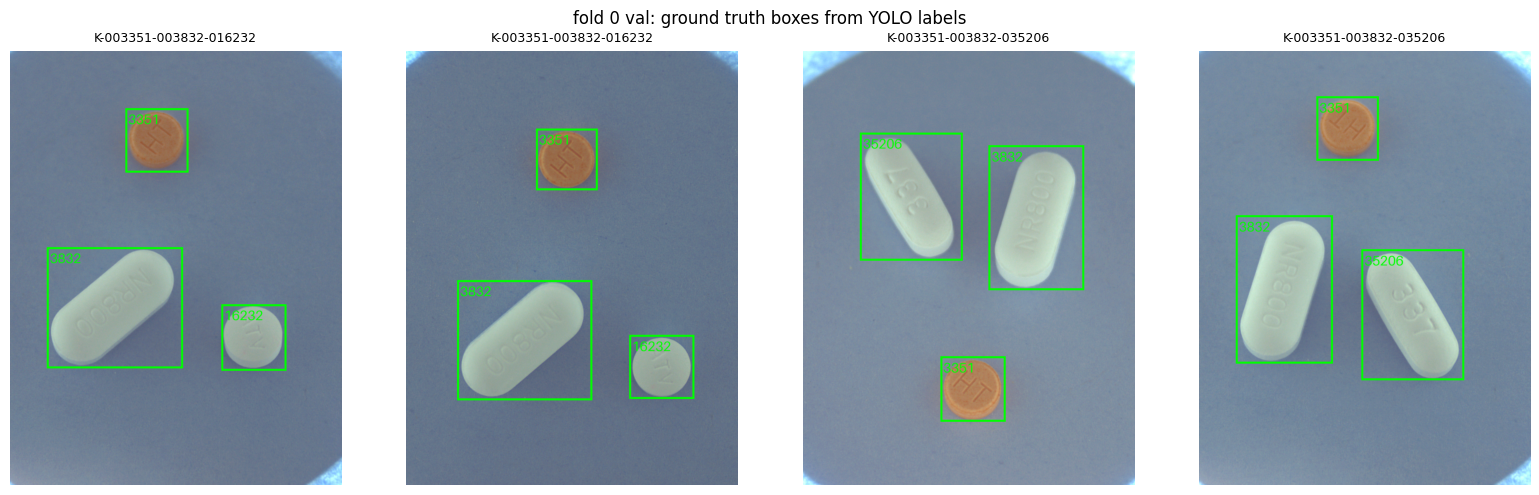

In [14]:
from PIL import Image as PILImage
from PIL import ImageDraw

check_class_map = load_class_map(LABEL)
idx_to_code = dict(zip(check_class_map["yolo_idx"], check_class_map["category_id"], strict=True))
sample_images = val_images[folds[0]][:4]
fig, axes = plt.subplots(1, len(sample_images), figsize=(4 * len(sample_images), 5), squeeze=False)
for ax, image_path in zip(axes[0], sample_images, strict=True):
    img = PILImage.open(image_path).convert("RGB")
    txt_path = yolo_dir(LABEL) / "labels" / "train" / f"{image_path.stem}.txt"
    draw = ImageDraw.Draw(img)
    for b in read_yolo_labels(txt_path, *img.size).itertuples():
        draw.rectangle([b.x, b.y, b.x + b.w, b.y + b.h], outline="lime", width=6)
        draw.text((b.x + 8, b.y + 8), str(idx_to_code[b.yolo_idx]), fill="lime", font_size=40)
    ax.imshow(img)
    ax.set_title(image_path.name.split("_")[0], fontsize=9)
    ax.axis("off")
fig.suptitle(f"fold {folds[0]} val: ground truth boxes from YOLO labels")
plt.tight_layout()
plt.show()

### 5-2. AI Hub 외부 데이터 추가 (02_eda §7)

> 출처: **02_eda** §1·2·5·6·7·8의 선별·검사 코드 — 사진 통째 사용, 외부 전용 알약 배경 처리, YOLO 변환, fold별 train 목록은 이 노트북에서 추가

`02_eda.ipynb` §7과 같은 방법·seed로 외부 bbox를 고르고, 그 bbox가 든 사진을 모든 fold의 train에 더합니다. val은 대회 사진 그대로입니다.

1. **선별 (02_eda §5~7)**: 대회 v1 라벨과 공통인 클래스마다 `AIHUB_TARGET_BBOX`(157)개가 되도록 부족한 수만큼 seed 42로 bbox를 뽑습니다. 좌표 오류·같은 약 중복 라벨이 있는 사진과 대회 사진과 이름이 같은 사진은 후보에서 뺍니다.
2. **문제 사진 제외 (02_eda §8)**: 파일명의 약 코드와 라벨이 다르거나(라벨 누락·파일명에 없는 라벨), bbox끼리 겹치거나(IoU > 0), 좌표가 잘못된 사진은 뺍니다. 02_eda §10~11의 OpenCV 보정은 사람 검수 전이라 적용하지 않습니다. JSON의 사진 크기와 실제 크기가 다른 사진, 대회 사진과 약 조합이 같은 사진(val 누수 가능)도 뺍니다.
3. **라벨**: 사진을 통째로 쓰므로 선택하지 않은 대회 알약도 모두 라벨링합니다. 그래서 클래스별 bbox는 157개를 넘을 수 있습니다. 대회 56종에 없는 **외부 전용 알약도 배경이 아닌 새 클래스로 라벨링**합니다 (`AIHUB_EXTRA_AS_CLASS = True`). 대회 번호 뒤에 0부터 이어지는 번호를 주고, `False`면 라벨 없이 배경으로 둡니다.
4. **YOLO 변환**: 외부 사진의 링크와 txt는 `data/processed/yolo/v1_aihub/`에 따로 만들고 파이프라인 폴더(`yolo/v1`)는 건드리지 않습니다. fold마다 `train.txt`는 대회 train + 외부 사진이고, `val.txt`는 파이프라인 파일을 그대로 씁니다. 외부 전용 클래스가 있으면 `data.yaml`의 `nc`·`names`를 대회 56종 뒤로 늘립니다.

선별 결과는 받은 zip에 따라 달라집니다. 이미지(TS) zip이 적으면 후보가 줄어 02_eda 머리말의 숫자(7,803 bbox / 5,499장)보다 적게 나옵니다. 실제로 쓴 bbox·라벨 목록은 `v1_aihub/aihub_selected.csv`·`aihub_labels.csv`에 저장하고, 검사 결과는 run 폴더의 `data_audit.json` → `aihub`에 남습니다.

Colab·Kaggle에서는 `AIHUB_URL`에서 zip을 받아 풉니다(Kaggle 디스크는 약 20GB). 이미 받았거나 다 푼 zip은 건너뜁니다. 로컬은 02_eda처럼 이미 푼 폴더(`.env`의 `AIHUB_EXTRACT_DIR`, 없으면 `data/external/aihub_combo`)만 씁니다.

In [16]:
!df -h /kaggle/working /kaggle/temp /tmp /


df: /kaggle/temp: No such file or directory
Filesystem      Size  Used Avail Use% Mounted on
/dev/loop2       20G   20G  292K 100% /kaggle/working
overlay         8.0T  7.1T  960G  89% /
overlay         8.0T  7.1T  960G  89% /


In [23]:
from data_process.aihub_data import (
    download_drive_folder,
    extract_zips,
    find_combo_zips,
    list_combo_images,
    load_combo_annotations,
    zip_key,
)

# 02_eda와 같은 위치. Colab·Kaggle은 올린 .env에 로컬 경로가 있어도 쓰지 않고 런타임 디스크를 쓴다.
aihub_extract_env = None if IN_REMOTE else os.getenv("AIHUB_EXTRACT_DIR")
aihub_extract_dir = Path(aihub_extract_env or "data/external/aihub_combo").expanduser()
if not aihub_extract_dir.is_absolute():
    aihub_extract_dir = PROJECT_ROOT / aihub_extract_dir
# Kaggle의 /kaggle/working은 20GB뿐이라 받는 zip(약 25GB)과 푼 파일은 /tmp에 둔다.
# 결과로 보존할 데이터가 아니고, 푼 zip은 바로 지워 최대 사용량을 줄인다.
aihub_zips_root = PROJECT_ROOT / "data" / "external" / "aihub_zips"
aihub_done_marker = None
if IN_KAGGLE:
    aihub_base = Path("/tmp/aihub")
    aihub_zips_root = aihub_base / "zips"
    aihub_extract_dir = aihub_base / "combo"
    aihub_done_marker = aihub_base / ".all_done"  # 전부 받고 푼 뒤에만 만든다. 있으면 다시 받지 않는다


def aihub_folders() -> list[Path]:
    """다 푼 외부 데이터 폴더 중 AIHUB_EXCLUDE에 없는 폴더를 이름순으로 반환한다 (02_eda §1)."""
    if not aihub_extract_dir.is_dir():
        return []
    return sorted(
        folder
        for folder in aihub_extract_dir.iterdir()
        if folder.is_dir()
        and not folder.name.startswith(".")
        and zip_key(folder) not in AIHUB_EXCLUDE
    )


if USE_AIHUB and IN_REMOTE and not (aihub_done_marker and aihub_done_marker.exists()):
    if AIHUB_COLAB_ZIP_DIR:
        aihub_zip_dir = Path(AIHUB_COLAB_ZIP_DIR)
    else:
        if not os.getenv("AIHUB_URL"):
            from getpass import getpass

            os.environ["AIHUB_URL"] = getpass(
                "AI Hub zip 폴더의 Drive 링크 AIHUB_URL (화면에 표시되지 않음): "
            ).strip()
        if not os.environ["AIHUB_URL"]:
            raise RuntimeError(
                "AIHUB_URL이 필요합니다. /content/.env, Colab 보안 비밀, Kaggle Secrets(AIHUB_URL)에 등록하세요."
            )
        # 이미 받은 파일은 건너뛰고 끊긴 파일은 이어 받는다
        aihub_zip_dir = download_drive_folder(
            os.environ["AIHUB_URL"], aihub_zips_root
        )
    aihub_zips = find_combo_zips(aihub_zip_dir, exclude=AIHUB_EXCLUDE)
    if not aihub_zips:
        raise FileNotFoundError(f"경로에 '조합'이 들어간 zip이 없습니다: {aihub_zip_dir}")
    print(f"조합 zip {len(aihub_zips)}개: {', '.join(path.name for path in aihub_zips)}")
    if IN_KAGGLE:
        # zip을 하나씩 풀고 바로 지워 디스크를 아낀다. 이미 푼 zip은 건너뛴다.
        for zip_path in aihub_zips:
            extract_zips([zip_path], aihub_extract_dir)
            if zip_path.is_relative_to(aihub_zips_root):  # Add Input 데이터셋(읽기 전용)은 지우지 않는다
                zip_path.unlink()
        aihub_done_marker.touch()
    else:
        extract_zips(aihub_zips, aihub_extract_dir)  # 이미 다 푼 zip은 건너뛴다

aihub_dirs = aihub_folders() if USE_AIHUB else []
if USE_AIHUB and not aihub_dirs:
    raise FileNotFoundError(
        f"압축을 푼 외부 데이터 폴더가 없습니다: {aihub_extract_dir}. "
        "로컬은 02_eda처럼 미리 풀어 두고, Colab·Kaggle은 AIHUB_URL을 확인하세요."
    )
if USE_AIHUB:
    print(f"외부 데이터 {aihub_extract_dir}: {', '.join(folder.name for folder in aihub_dirs)}")
else:
    print("USE_AIHUB=False: 외부 데이터 없이 대회 데이터만 학습합니다.")


조합 zip 14개: TL_1_조합.zip, TL_3_조합.zip, TL_4_조합.zip, TL_5_조합.zip, TL_6_조합.zip, TL_7_조합.zip, TL_8_조합.zip, TS_1_조합.zip, TS_3_조합.zip, TS_4_조합.zip, TS_5_조합.zip, TS_6_조합.zip, TS_7_조합.zip, VL_1_조합.zip
풀기 완료: TL_1_조합 (6011개 파일)
풀기 완료: TL_3_조합 (5732개 파일)
풀기 완료: TL_4_조합 (5466개 파일)
풀기 완료: TL_5_조합 (5997개 파일)
풀기 완료: TL_6_조합 (6000개 파일)
풀기 완료: TL_7_조합 (5565개 파일)
풀기 완료: TL_8_조합 (5643개 파일)
풀기 완료: TS_1_조합 (2012개 파일)
풀기 완료: TS_3_조합 (2000개 파일)
풀기 완료: TS_4_조합 (2000개 파일)
풀기 완료: TS_5_조합 (2000개 파일)
풀기 완료: TS_6_조합 (2000개 파일)
풀기 완료: TS_7_조합 (2000개 파일)
풀기 완료: VL_1_조합 (5520개 파일)
외부 데이터 /tmp/aihub/combo: TL_1_조합, TL_3_조합, TL_4_조합, TL_5_조합, TL_6_조합, TL_7_조합, TL_8_조합, TS_1_조합, TS_3_조합, TS_4_조합, TS_5_조합, TS_6_조합, TS_7_조합, VL_1_조합


In [22]:
import os
AIHUB_COLAB_ZIP_DIR = "/tmp/aihub/zips"
print(sorted(os.listdir(AIHUB_COLAB_ZIP_DIR)))


['TL_1_조합.zip', 'TL_3_조합.zip', 'TL_4_조합.zip', 'TL_5_조합.zip', 'TL_6_조합.zip', 'TL_7_조합.zip', 'TL_8_조합.zip', 'TS_1_조합.zip', 'TS_3_조합.zip', 'TS_4_조합.zip', 'TS_5_조합.zip', 'TS_6_조합.zip', 'TS_7_조합.zip', 'VL_1_조합.zip']


In [20]:
!ls -la /tmp/aihub/zips


total 21414372
drwxr-xr-x 2 root root       4096 Nov  3 02:07 .
drwxr-xr-x 3 root root       4096 Nov  3 01:59 ..
-rw------- 1 root root    8220381 Oct 29 08:17 TL_1_조합.zip
-rw------- 1 root root    7740485 Oct 29 08:17 TL_3_조합.zip
-rw------- 1 root root    7289648 Oct 29 08:17 TL_4_조합.zip
-rw------- 1 root root    8136663 Oct 29 08:17 TL_5_조합.zip
-rw------- 1 root root    8093059 Oct 29 08:17 TL_6_조합.zip
-rw------- 1 root root    7613790 Oct 29 08:17 TL_7_조합.zip
-rw------- 1 root root    7705416 Oct 29 08:17 TL_8_조합.zip
-rw------- 1 root root 3710983751 Oct 29 08:17 TS_1_조합.zip
-rw------- 1 root root 3650633084 Oct 29 08:17 TS_3_조합.zip
-rw------- 1 root root 3571751311 Oct 29 08:17 TS_4_조합.zip
-rw------- 1 root root 3622478219 Oct 29 08:18 TS_5_조합.zip
-rw------- 1 root root 3675209724 Oct 29 08:18 TS_6_조합.zip
-rw------- 1 root root 3635086527 Oct 29 08:18 TS_7_조합.zip
-rw------- 1 root root    7323186 Oct 29 08:18 VL_1_조합.zip


항목,개수
외부 이미지 (푼 폴더 전체),12012
외부 bbox 라벨 (푼 폴더 전체),45933
공통 클래스 (대회 v1 ∩ 외부),54
02_eda §7 선택 bbox,7384
선택 bbox가 든 사진,4820
제외: 라벨 누락,23
제외: 파일명에 없는 라벨,0
제외: bbox 겹침,75
제외: 좌표·중복 오류,0
제외: JSON·실제 크기 다름,0


합계가 목표 157개 미만인 클래스: 15/56종


,dl_name,대회 v1,02_eda 선택,외부 학습 라벨,합계
category_id,,,,,
3743,알드린정,3,154,256,259
13395,써스펜8시간이알서방정 650mg,3,154,206,209
12247,아빌리파이정 10mg,3,154,294,297
12081,리렉스펜정 300mg/PTP,3,154,207,210
22362,맥시부펜이알정 300mg,3,154,201,204
21771,라비에트정 20mg,3,154,180,183
19552,트루비타정 60mg/병,3,154,247,250
16551,동아가바펜틴정 800mg,3,154,691,694
33009,신바로정,3,154,167,170


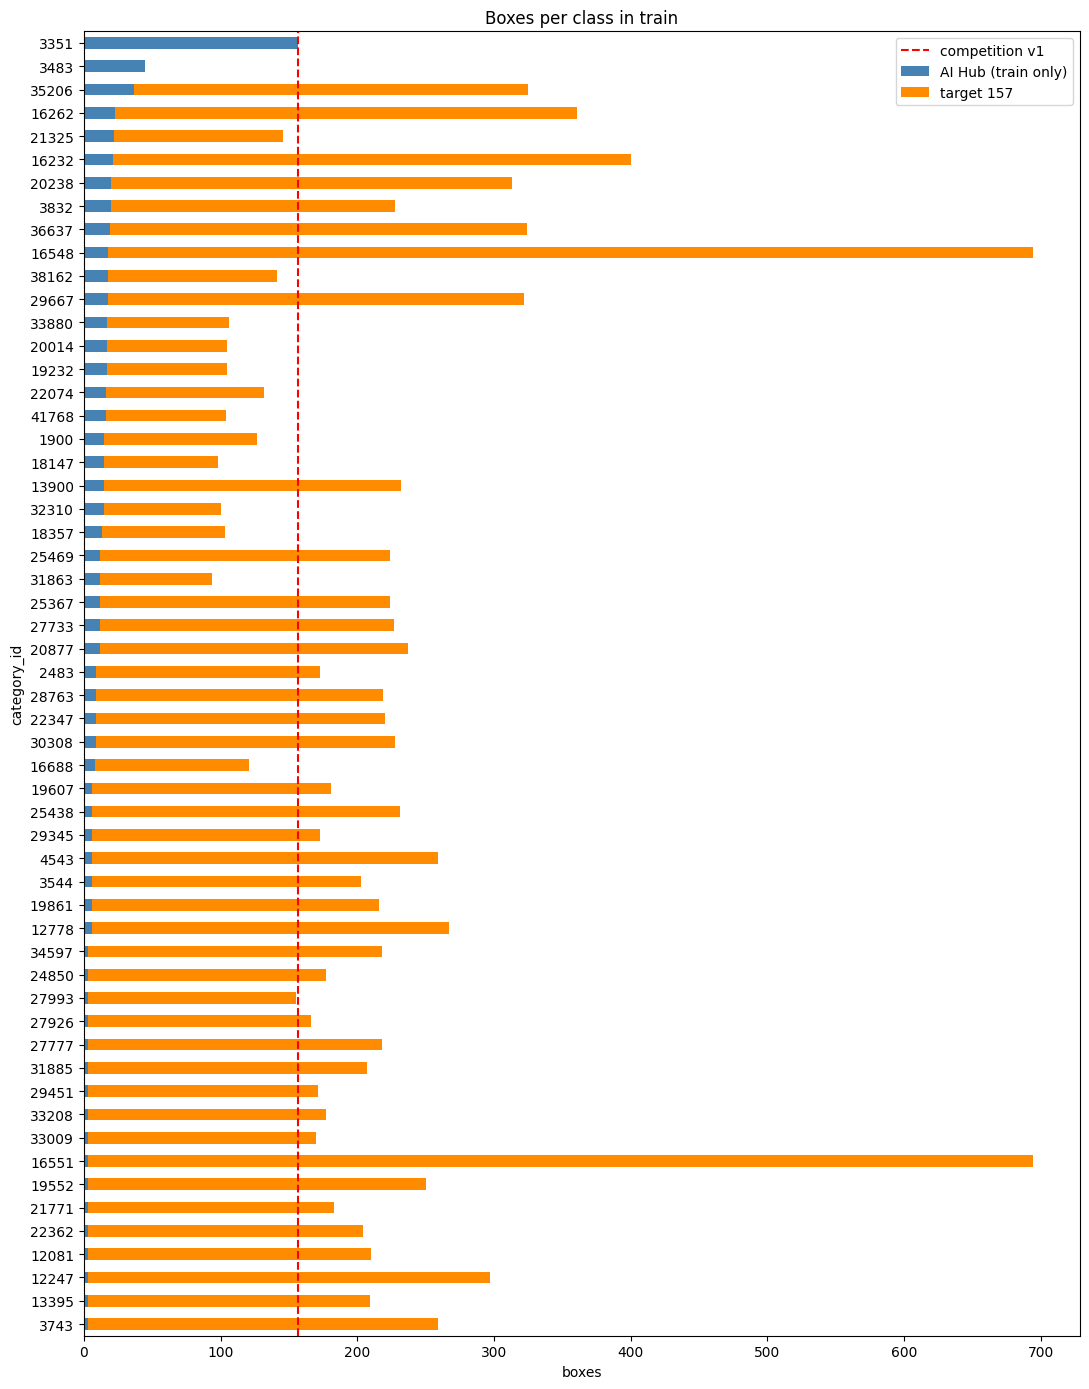

In [24]:
from data_process.data_processing import (
    bbox_flags,
    find_box_pairs,
    list_images,
    read_image_headers,
)

BOX_NUMBERS = ["x", "y", "w", "h", "width", "height"]
aihub_raw_dir = PROJECT_ROOT / "data" / "raw"
if (aihub_raw_dir / "sprint_ai_project1_data").is_dir():
    aihub_raw_dir = aihub_raw_dir / "sprint_ai_project1_data"


def name_codes(file_name: str) -> set[int]:
    """파일명 앞 조합(K-001900-003544-...)의 약 코드 집합. 사진에서 센 알약 수가 아니다."""
    return {int(code) for code in file_name.split("_")[0].split("-")[1:]}


def select_aihub_images(dirs: list[Path], comp_labels: pd.DataFrame) -> dict:
    """02_eda §1·2·5·6·7과 같이 bbox를 고르고 §8 검사로 쓸 사진·라벨·배경 알약을 나눈다."""
    # §1·2: 이미지와 라벨 연결. 같은 이름이 여러 폴더에 있으면 라벨을 안전하게 붙일 수 없다.
    image_index = list_combo_images(dirs)
    if image_index.empty:
        raise FileNotFoundError("외부 이미지가 없습니다. TS 원천 이미지 폴더를 확인하세요.")
    if image_index["file_name"].duplicated().any():
        raise ValueError("외부 이미지 이름이 중복됩니다. 02_eda §1에서 중복 목록을 확인하세요.")
    ann_df, _ = load_combo_annotations(dirs)
    if ann_df.empty or ann_df["category_id"].isna().any():
        raise ValueError("외부 라벨이 없거나 약 코드를 해석할 수 없는 bbox가 있습니다 (02_eda §2).")
    available = ann_df[ann_df["file_name"].isin(set(image_index["file_name"]))].copy()

    # §5: 대회 v1과 공통인 클래스마다 목표까지 부족한 bbox 수
    comp_counts = comp_labels.groupby("category_id").size()
    common = sorted(set(comp_counts.index) & set(available["category_id"].astype(int)))
    needed = (AIHUB_TARGET_BBOX - comp_counts).clip(lower=0)

    # §6: 좌표·중복 오류가 있는 사진과 대회 사진과 같은 이름은 후보에서 뺀다
    candidates = available[available["category_id"].isin(common)].merge(
        image_index[["file_name", "path"]], on="file_name", validate="many_to_one"
    )
    numeric = available[BOX_NUMBERS].apply(pd.to_numeric, errors="coerce")
    flags = bbox_flags(available)
    invalid_box = (
        ~np.isfinite(numeric).all(axis=1)
        | numeric[["width", "height"]].le(0).any(axis=1)
        | flags["out_of_image"]
        | flags["non_positive"]
        | available.duplicated(["file_name", "category_id"], keep=False)
    )
    invalid_files = set(available.loc[invalid_box, "file_name"])
    comp_names = {
        path.name
        for split in ("train", "test")
        for path in list_images(aihub_raw_dir / f"{split}_images")
    }
    comp_combos = set(comp_labels["file_name"].str.split("_").str[0])
    comp_combos |= {name.split("_")[0] for name in comp_names if name.startswith("K-")}

    # §7: 클래스별 부족량만큼 seed로 비복원 추출한다
    pool = candidates[~candidates["file_name"].isin(invalid_files | comp_names)].copy()
    pool["combo"] = pool["file_name"].str.split("_").str[0]
    pool["shares_competition_combo"] = pool["combo"].isin(comp_combos)
    pool = pool.drop_duplicates(["file_name", "category_id", "x", "y", "w", "h"])
    shuffled = pool.sample(frac=1, random_state=SEED)
    order = shuffled.groupby("category_id").cumcount()
    selected = (
        shuffled[order.lt(shuffled["category_id"].map(needed))]
        .sort_values(["category_id", "file_name"])
        .reset_index(drop=True)
    )

    # §8: 선택 bbox가 든 사진 전체의 라벨을 검사한다. 사진을 통째로 쓰므로 함께 찍힌 bbox도 본다.
    files = sorted(selected["file_name"].unique())
    boxes = available[available["file_name"].isin(files)].copy()
    boxes["category_id"] = boxes["category_id"].astype(int)
    numeric = boxes[BOX_NUMBERS].apply(pd.to_numeric, errors="coerce")
    valid = np.isfinite(numeric).all(axis=1) & numeric[["w", "h", "width", "height"]].gt(0).all(
        axis=1
    )
    invalid = (
        ~valid
        | bbox_flags(boxes)["out_of_image"]
        | boxes.duplicated(["file_name", "category_id"], keep=False)
    )
    pairs = find_box_pairs(boxes[valid], max_gap=0)
    labeled = boxes.groupby("file_name")["category_id"].agg(set)
    paths = image_index.set_index("file_name")["path"]
    headers = read_image_headers([paths[name] for name in files], "aihub").set_index("file_name")
    json_size = boxes.groupby("file_name")[["width", "height"]].first()
    reasons = pd.DataFrame(index=pd.Index(files, name="file_name"))
    reasons["라벨 누락"] = [bool(name_codes(name) - labeled[name]) for name in files]
    reasons["파일명에 없는 라벨"] = [bool(labeled[name] - name_codes(name)) for name in files]
    reasons["bbox 겹침"] = reasons.index.isin(set(pairs.loc[pairs["iou"].gt(0), "file_name"]))
    reasons["좌표·중복 오류"] = reasons.index.isin(set(boxes.loc[invalid, "file_name"]))
    real_size = headers.loc[files, ["width", "height"]].to_numpy()
    reasons["JSON·실제 크기 다름"] = (real_size != json_size.loc[files].to_numpy()).any(axis=1)
    # 대회 사진과 약 조합이 같으면 같은 조합의 대회 val 사진과 겹칠 수 있다
    reasons["대회와 같은 조합"] = reasons.index.str.split("_").str[0].isin(comp_combos)

    comp_ids = set(comp_labels["category_id"].astype(int))
    kept = boxes[boxes["file_name"].isin(reasons.index[~reasons.any(axis=1)])]
    return {
        "n_images": len(image_index),
        "n_labels": len(ann_df),
        "common_classes": common,
        "selected": selected,
        "reasons": reasons,
        "labels": kept[kept["category_id"].isin(comp_ids)].copy(),
        "background": kept[~kept["category_id"].isin(comp_ids)].copy(),
        "paths": paths,
    }


if USE_AIHUB:
    comp_labels = pd.read_csv(PROJECT_ROOT / "data/processed/labels" / f"labels_{LABEL}.csv")
    aihub = select_aihub_images(aihub_dirs, comp_labels)
    aihub_labels, aihub_reasons = aihub["labels"], aihub["reasons"]
    aihub_files = sorted(aihub_labels["file_name"].unique())
    if aihub_files != sorted(aihub_reasons.index[~aihub_reasons.any(axis=1)]):
        raise ValueError("대회 클래스 라벨이 없는 외부 사진이 있습니다.")
    aihub_summary = [
        ("외부 이미지 (푼 폴더 전체)", aihub["n_images"]),
        ("외부 bbox 라벨 (푼 폴더 전체)", aihub["n_labels"]),
        ("공통 클래스 (대회 v1 ∩ 외부)", len(aihub["common_classes"])),
        ("02_eda §7 선택 bbox", len(aihub["selected"])),
        ("선택 bbox가 든 사진", len(aihub_reasons)),
        *[(f"  제외: {column}", int(aihub_reasons[column].sum())) for column in aihub_reasons],
        ("제외한 사진 (사유가 여럿이어도 한 번)", int(aihub_reasons.any(axis=1).sum())),
        ("train에 더할 사진", len(aihub_files)),
        ("학습 라벨 bbox (대회 클래스, 선택 + 함께 찍힌 것)", len(aihub_labels)),
        ("외부 전용 알약 (새 클래스 또는 배경)", len(aihub["background"])),
    ]
    display(pd.DataFrame(aihub_summary, columns=["항목", "개수"]).style.hide(axis="index"))

    aihub_classes = load_class_map(LABEL).set_index("category_id")[["dl_name"]]
    aihub_classes["대회 v1"] = comp_labels.groupby("category_id").size()
    aihub_classes["02_eda 선택"] = aihub["selected"].groupby("category_id").size()
    aihub_classes["외부 학습 라벨"] = aihub_labels.groupby("category_id").size()
    count_columns = ["대회 v1", "02_eda 선택", "외부 학습 라벨"]
    aihub_classes[count_columns] = aihub_classes[count_columns].fillna(0).astype(int)
    aihub_classes["합계"] = aihub_classes["대회 v1"] + aihub_classes["외부 학습 라벨"]
    aihub_classes = aihub_classes.sort_values("대회 v1")
    n_short = int(aihub_classes["합계"].lt(AIHUB_TARGET_BBOX).sum())
    print(f"합계가 목표 {AIHUB_TARGET_BBOX}개 미만인 클래스: {n_short}/{len(aihub_classes)}종")
    with pd.option_context("display.max_rows", None):
        display(aihub_classes)
    ax = aihub_classes[["대회 v1", "외부 학습 라벨"]].plot.barh(
        stacked=True, figsize=(11, 14), color=["steelblue", "darkorange"]
    )
    ax.axvline(AIHUB_TARGET_BBOX, color="red", linestyle="--")
    ax.legend(["competition v1", "AI Hub (train only)", f"target {AIHUB_TARGET_BBOX}"])
    ax.set(title="Boxes per class in train", xlabel="boxes", ylabel="category_id")
    plt.tight_layout()
    plt.show()

In [25]:
from data_process.make_labels import write_yolo_labels
from data_process.move_files import link_images

AIHUB_YOLO_DIR = yolo_dir(f"{LABEL}_aihub")  # data/processed/yolo/v1_aihub. 파이프라인 폴더와 따로
aihub_image_dir = AIHUB_YOLO_DIR / "images" / "train"
aihub_label_dir = AIHUB_YOLO_DIR / "labels" / "train"


def list_path(data: dict, split: str) -> Path:
    """data.yaml의 train·val 목록 파일 경로."""
    path = Path(data[split])
    return path if path.is_absolute() else Path(data["path"]) / path


def read_list(path: Path) -> list[str]:
    """목록 txt의 이미지 경로를 빈 줄 없이 읽는다."""
    return [line.strip() for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]


train_data_paths = {}
# 외부 전용 알약 클래스 표. AIHUB_EXTRA_AS_CLASS일 때만 아래 else 블록에서 채운다
aihub_extra_map = pd.DataFrame(
    {
        "yolo_idx": pd.Series(dtype=int),
        "category_id": pd.Series(dtype=int),
        "dl_name": pd.Series(dtype=str),
    }
)
aihub_extra_names = {}
if not USE_AIHUB:
    train_data_paths = dict(data_paths)
    data_audit["aihub"] = {"used": False, "folds": list(folds)}
else:
    # 외부 사진 링크와 YOLO 라벨. 대회 클래스는 대회 번호로 쓰고, 외부 전용 알약은 아래 설정에 따라 새 클래스 또는 배경이다.
    aihub_class_map = load_class_map(LABEL)
    aihub_class_idx = dict(
        zip(
            aihub_class_map["category_id"].astype(int),
            aihub_class_map["yolo_idx"].astype(int),
            strict=True,
        )
    )
    # 외부 전용 알약: 배경이 아니라 대회 클래스 수 뒤의 새 번호로 라벨링한다 (끄면 라벨 없이 배경)
    aihub_train_labels = aihub_labels
    if AIHUB_EXTRA_AS_CLASS:
        extra = aihub["background"].drop_duplicates("category_id").sort_values("category_id")
        aihub_extra_map = pd.DataFrame(
            {
                "yolo_idx": range(len(aihub_class_map), len(aihub_class_map) + len(extra)),
                "category_id": extra["category_id"].astype(int).to_numpy(),
                "dl_name": extra["dl_name"].to_numpy(),
            }
        )
        extra_ids = aihub_extra_map["yolo_idx"].tolist()
        aihub_extra_names = dict(zip(extra_ids, aihub_extra_map["dl_name"].tolist(), strict=True))
        aihub_class_idx.update(zip(aihub_extra_map["category_id"].tolist(), extra_ids, strict=True))
        aihub_train_labels = pd.concat([aihub_labels, aihub["background"]], ignore_index=True)
    link_counts = link_images([aihub["paths"][name] for name in aihub_files], aihub_image_dir)
    yolo_counts = write_yolo_labels(
        aihub_train_labels, aihub_files, aihub_class_idx, aihub_label_dir
    )
    aihub_manifest = []
    max_error = 0.0
    yolo_columns = ["yolo_idx", "x", "y", "w", "h"]
    for file_name, rows in aihub_train_labels.groupby("file_name"):
        txt_path = aihub_label_dir / Path(file_name).with_suffix(".txt").name
        back = read_yolo_labels(txt_path, rows["width"].iloc[0], rows["height"].iloc[0])
        expected = rows.assign(yolo_idx=rows["category_id"].map(aihub_class_idx))
        if len(back) != len(expected) or expected["yolo_idx"].isna().any():
            raise ValueError(f"외부 YOLO 라벨 개수나 클래스가 다릅니다: {file_name}")
        error = np.abs(
            back[yolo_columns].sort_values(yolo_columns).to_numpy(dtype=float)
            - expected[yolo_columns].sort_values(yolo_columns).to_numpy(dtype=float)
        ).max()
        max_error = max(max_error, float(error))
        aihub_manifest.append(txt_path)
    if (
        max_error > 0.01
        or yolo_counts["n_dropped"]
        or yolo_counts["n_empty"]
        or yolo_counts["n_lines"] != len(aihub_train_labels)
    ):
        raise ValueError(f"외부 YOLO 라벨 검사 실패: {yolo_counts}, 오차={max_error}px")

    # 실제로 쓴 선택 bbox와 학습 라벨을 남긴다
    keep_columns = [
        "file_name",
        "zip_name",
        "source_json",
        "annotation_id",
        "category_id",
        "dl_name",
        *BOX_NUMBERS,
    ]
    for name, frame in [
        ("aihub_selected", aihub["selected"]),
        ("aihub_labels", aihub_train_labels),
    ]:
        frame[keep_columns].to_csv(AIHUB_YOLO_DIR / f"{name}.csv", index=False, encoding="utf-8")
        aihub_manifest.append(AIHUB_YOLO_DIR / f"{name}.csv")

    # fold마다 train = 대회 train + 외부 사진, val = 파이프라인 val.txt 그대로
    aihub_images = [str(aihub_image_dir / name) for name in aihub_files]
    aihub_combos = {name.split("_")[0] for name in aihub_files}
    aihub_fold_rows = []
    for fold in folds:
        base = yaml.safe_load(data_paths[fold].read_text(encoding="utf-8"))
        comp_train = read_list(list_path(base, "train"))
        val_path = list_path(base, "val")
        val_names = {Path(line).name for line in read_list(val_path)}
        comp_names = val_names | {Path(line).name for line in comp_train}
        val_combos = {name.split("_")[0] for name in val_names}
        if set(aihub_files) & comp_names or aihub_combos & val_combos:
            raise ValueError(f"fold {fold}: 외부 사진이 대회 사진이나 val 조합과 겹칩니다.")
        out_dir = AIHUB_YOLO_DIR / "splits" / SPLIT / f"fold_{fold}"
        out_dir.mkdir(parents=True, exist_ok=True)
        train_txt = out_dir / "train.txt"
        train_txt.write_text(
            "".join(f"{path}\n" for path in comp_train + aihub_images), encoding="utf-8"
        )
        names = {**base["names"], **aihub_extra_names}
        data = {
            "path": base["path"],
            "train": str(train_txt),
            "val": str(val_path),
            "nc": len(names),
            "names": names,
        }
        header = {
            "label_version": LABEL,
            "split_name": SPLIT,
            "fold": fold,
            "aihub_images": len(aihub_images),
            "extra_classes": len(aihub_extra_names),
        }
        yaml_path = out_dir / "data.yaml"
        yaml_path.write_text(
            "".join(f"# {key}: {value}\n" for key, value in header.items())
            + yaml.safe_dump(data, allow_unicode=True, sort_keys=False),
            encoding="utf-8",
        )
        train_data_paths[fold] = yaml_path
        aihub_manifest.extend([train_txt, yaml_path])
        n_train = len(comp_train) + len(aihub_images)
        aihub_fold_rows.append(
            {
                "fold": fold,
                "대회 train": len(comp_train),
                "외부 train": len(aihub_images),
                "train 합계": n_train,
                "val (대회)": len(val_names),
                "train 배수": round(n_train / len(comp_train), 1),
            }
        )

    # 학습 셀의 데이터 지문 검사에 외부 라벨·목록도 넣는다. 다시 실행해도 이전 외부 파일은 뺀다.
    aihub_prefix = AIHUB_YOLO_DIR.relative_to(PROJECT_ROOT).as_posix() + "/"
    data_audit["files"] = sorted(
        {name for name in data_audit["files"] if not name.startswith(aihub_prefix)}
        | {path.relative_to(PROJECT_ROOT).as_posix() for path in aihub_manifest}
    )
    data_audit["fingerprint"] = files_sha256(
        [PROJECT_ROOT / name for name in data_audit["files"]], PROJECT_ROOT
    )
    data_audit["aihub"] = {
        "used": True,
        "source": "notebooks/02_eda.ipynb §1·2·5·6·7·8",
        "folds": list(folds),
        "folders": [folder.name for folder in aihub_dirs],
        "exclude": list(AIHUB_EXCLUDE),
        "target_bbox": AIHUB_TARGET_BBOX,
        "seed": SEED,
        "selected_bbox": len(aihub["selected"]),
        "selected_images": len(aihub_reasons),
        "excluded_images": {column: int(aihub_reasons[column].sum()) for column in aihub_reasons},
        "train_images": len(aihub_files),
        "train_labels": len(aihub_train_labels),
        "extra_classes": len(aihub_extra_names),
        "background_pills": len(aihub["background"]),
        "background_policy": (
            "대회 56종 밖 외부 전용 알약은 새 클래스로 학습"
            if AIHUB_EXTRA_AS_CLASS
            else "대회 56종에 없는 외부 전용 알약은 라벨 없이 배경으로 둔다"
        ),
        "yolo_dir": aihub_prefix.rstrip("/"),
        "yolo_max_roundtrip_error_px": max_error,
        "fold_counts": aihub_fold_rows,
    }
    print(
        f"외부 사진 링크 {link_counts}, YOLO 라벨 {yolo_counts}, 역변환 최대 오차 {max_error:.4f}px"
    )
    print("외부 사진과 대회 사진·val 조합 겹침 0 확인. val은 파이프라인 val.txt 그대로입니다.")
    display(pd.DataFrame(aihub_fold_rows))
    print("에폭당 학습 시간은 train 사진 수에 비례해 대략 'train 배수'만큼 늘어납니다.")

외부 사진 링크 {'symlink': 4722, 'copy': 0, 'kept': 0}, YOLO 라벨 {'n_txt': 4722, 'n_lines': 17770, 'n_dropped': 0, 'n_empty': 0}, 역변환 최대 오차 0.0010px
외부 사진과 대회 사진·val 조합 겹침 0 확인. val은 파이프라인 val.txt 그대로입니다.


,fold,대회 train,외부 train,train 합계,val (대회),train 배수
0,0,195,4722,4917,37,25.2


에폭당 학습 시간은 train 사진 수에 비례해 대략 'train 배수'만큼 늘어납니다.


#### 외부 사진 눈으로 확인

외부 train 사진 4장에 YOLO txt에서 되돌린 박스를 그립니다. 초록은 학습 라벨입니다. `AIHUB_EXTRA_AS_CLASS = True`면 외부 전용 알약도 초록 라벨(대회 번호 뒤의 새 클래스)로 표시합니다. `False`면 라벨 없이 배경으로 둔 외부 전용 알약을 회색 `bg`로만 표시하고, 회색 박스는 학습에 들어가지 않습니다.

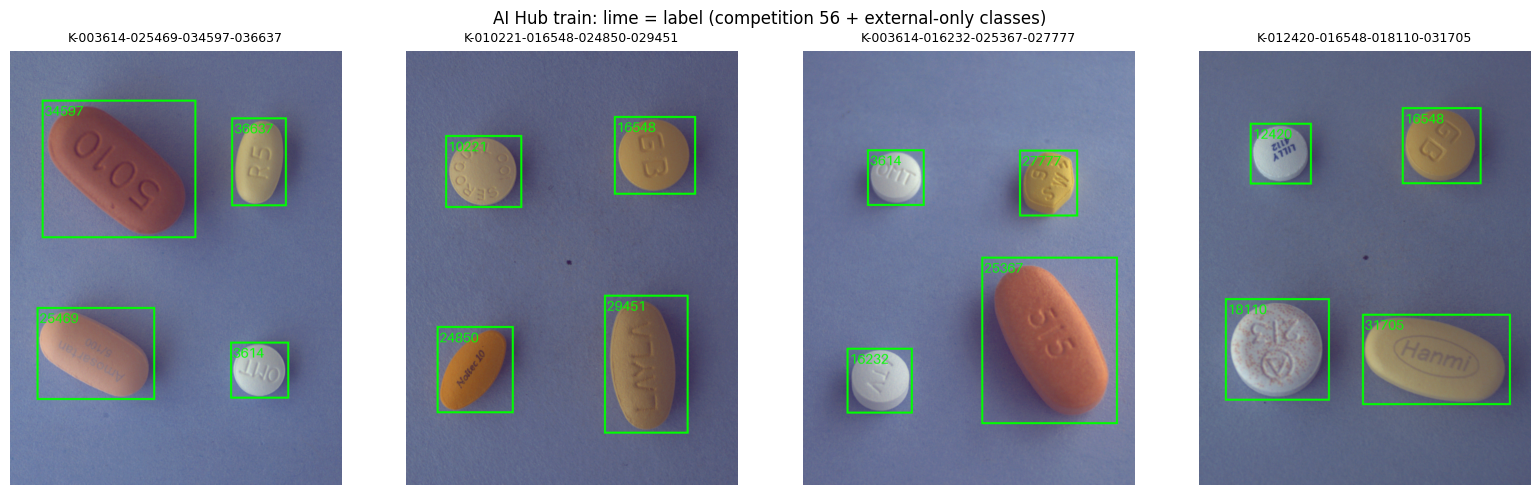

In [26]:
from PIL import Image as PILImage
from PIL import ImageDraw

if USE_AIHUB:
    aihub_idx_to_code = {index: code for code, index in aihub_class_idx.items()}
    # 배경 알약이 있는 사진을 먼저 보여 준다
    preview_pool = sorted(set(aihub["background"]["file_name"])) or aihub_files
    preview_files = pd.Series(preview_pool).sample(n=min(4, len(preview_pool)), random_state=SEED)
    fig, axes = plt.subplots(
        1, len(preview_files), figsize=(4 * len(preview_files), 5), squeeze=False
    )
    for ax, file_name in zip(axes[0], preview_files, strict=True):
        img = PILImage.open(aihub_image_dir / file_name).convert("RGB")
        draw = ImageDraw.Draw(img)
        txt_path = aihub_label_dir / Path(file_name).with_suffix(".txt").name
        for b in read_yolo_labels(txt_path, *img.size).itertuples():
            draw.rectangle([b.x, b.y, b.x + b.w, b.y + b.h], outline="lime", width=6)
            label = str(aihub_idx_to_code[b.yolo_idx])
            draw.text((b.x + 8, b.y + 8), label, fill="lime", font_size=40)
        background = aihub["background"][aihub["background"]["file_name"].eq(file_name)]
        if AIHUB_EXTRA_AS_CLASS:  # 외부 전용 알약도 위에서 초록 라벨로 그렸다
            background = background.iloc[0:0]
        for b in background.itertuples():
            draw.rectangle([b.x, b.y, b.x + b.w, b.y + b.h], outline="gray", width=4)
            draw.text((b.x + 8, b.y + 8), f"bg {b.category_id}", fill="gray", font_size=40)
        ax.imshow(img)
        ax.set_title(file_name.split("_")[0], fontsize=9)
        ax.axis("off")
    fig.suptitle(
        "AI Hub train: lime = label (competition 56 + external-only classes)"
        if AIHUB_EXTRA_AS_CLASS
        else "AI Hub train: lime = label (competition class), gray = background (external-only)"
    )
    plt.tight_layout()
    plt.show()

## 6. 노트북 전용 학습 루프

> 출처: **권영현+강재민** — 학습 루프는 강재민, 검증 기울기 확인 `GradCheck`는 권영현

Ultralytics의 학습 루프를 상속해서 매 epoch validation을 실행합니다.
validation은 `eval()` 모드와 기울기 계산 비활성화 상태에서 실행합니다.
`best.pt` 선택과 early stopping에는 mAP@[0.75:0.95]를 사용하며 0점이 이어져도 중단 횟수를 셉니다.
매 epoch train/validation loss와 Precision·Recall·mAP75–95를 출력하고 `results.csv`에 저장합니다.

`GradCheck`(권영현)는 학습 배치와 검증 배치 안에서 `torch.is_grad_enabled()`를 기록합니다. 모든 epoch에서 학습 중 `True`, 검증 중 `False`면 검증에서 기울기가 실제로 꺼진 것입니다.

In [ ]:
MAIN_METRIC_KEY = "metrics/mAP75-95(B)"
INFERENCE_METRIC_KEY = "speed/inference_ms"


def map75_95(box: object) -> float:
    """IoU 0.75, 0.80, 0.85, 0.90, 0.95의 클래스별 AP를 평균한다."""
    all_ap = np.asarray(box.all_ap)
    return float(all_ap[:, 5:].mean()) if len(all_ap) else 0.0


class NotebookEarlyStopping(EarlyStopping):
    """같은 점수와 0점도 개선 없음으로 세어 patience 후 중단한다."""

    def __call__(self, epoch: int, fitness: float | None) -> bool:
        if fitness is None:
            return False
        if self.best_epoch == 0 or fitness > self.best_fitness:
            self.best_epoch, self.best_fitness = epoch, fitness
        delta = epoch - self.best_epoch
        self.possible_stop = delta >= self.patience - 1
        stop = delta >= self.patience
        if stop:
            LOGGER.info(
                f"EarlyStopping: {self.patience:g} epoch 동안 개선 없음, "
                f"최고 epoch={self.best_epoch}, 체크포인트=best.pt"
            )
        return stop


class NotebookTrainer(DetectionTrainer):
    """이 노트북에서만 mAP75-95로 최고 체크포인트와 조기 중단을 결정한다."""

    def _setup_train(self) -> None:
        super()._setup_train()
        stopper = NotebookEarlyStopping(self.args.patience)
        stopper.best_epoch = self.stopper.best_epoch
        stopper.best_fitness = self.stopper.best_fitness
        stopper.possible_stop = self.stopper.possible_stop
        self.stopper = stopper

    def save_model(self) -> bool:
        """best·last 저장을 유지하고 완료한 에폭 수 기준으로 주기 체크포인트를 저장한다."""
        period = self.save_period
        # 라이브러리 내부의 0부터 시작하는 저장 주기는 끄고 5·10·15에폭 완료에 맞춘다.
        self.save_period = -1
        try:
            saved = super().save_model()
        finally:
            self.save_period = period
        completed_epochs = self.epoch + 1
        if saved and period > 0 and completed_epochs % period == 0:
            checkpoint_path = self.wdir / f"epoch{completed_epochs}.pt"
            shutil.copyfile(self.last, checkpoint_path)
            LOGGER.info(f"{completed_epochs}에폭 완료 체크포인트: {checkpoint_path}")
        return saved

    @torch.no_grad()
    def validate(self) -> tuple[dict | None, float | None]:
        previous_best = self.best_fitness
        # 기본 validator도 내부에서 eval()과 inference mode를 사용한다.
        metrics, fitness = super().validate()
        if metrics is None:
            return metrics, fitness
        fitness = map75_95(self.validator.metrics.box)
        metrics[MAIN_METRIC_KEY] = round(fitness, 5)
        metrics[INFERENCE_METRIC_KEY] = float(self.validator.speed["inference"])
        # 부모가 기본 mAP50-95로 갱신한 best_fitness를 주 지표 기준으로 다시 정한다.
        self.best_fitness = fitness if previous_best is None else max(previous_best, fitness)
        values = {**self.label_loss_items(self.tloss), **metrics}
        text = ", ".join(f"{key}={float(value):.5f}" for key, value in values.items())
        LOGGER.info(f"epoch {self.epoch + 1}: {text}")
        return metrics, fitness


class EpochTimer:
    """에폭별 학습·검증·체크포인트 저장 시간을 진행 바와 CSV로 기록한다."""

    def __init__(self, fold: int) -> None:
        self.fold = fold
        self.progress = None
        self.started_at: float | None = None
        self.active_epoch: int | None = None
        self.rows: list[dict] = []

    def on_train_start(self, trainer: DetectionTrainer) -> None:
        """배치 진행 바와 별도로 전체 에폭 진행 바를 시작한다."""
        self.progress = tqdm(
            total=trainer.epochs,
            initial=trainer.start_epoch,
            desc=f"fold {self.fold} / epochs",
            unit="epoch",
            dynamic_ncols=True,
            mininterval=TQDM_MININTERVAL,
            leave=True,
        )

    def on_epoch_start(self, trainer: DetectionTrainer) -> None:
        """에폭 재시도 시간이 빠지지 않도록 최초 시작 시각을 유지한다."""
        epoch = trainer.epoch + 1
        if self.active_epoch != epoch:
            self.active_epoch = epoch
            self.started_at = perf_counter()

    def on_epoch_end(self, trainer: DetectionTrainer) -> None:
        """검증과 저장이 끝나면 시간을 기록하고, 최종 best 재검증 호출은 제외한다."""
        if self.started_at is None:
            return
        seconds = perf_counter() - self.started_at
        self.started_at = None
        self.active_epoch = None
        epoch = trainer.epoch + 1
        elapsed = sum(row["epoch_seconds"] for row in self.rows) + seconds
        average = elapsed / (len(self.rows) + 1)
        remaining = max(trainer.epochs - epoch, 0) * average
        self.rows.append(
            {
                "epoch": epoch,
                "epoch_seconds": seconds,
                "cumulative_seconds": elapsed,
                "estimated_remaining_seconds": remaining,
            }
        )
        pd.DataFrame(self.rows).to_csv(Path(trainer.save_dir) / "epoch_times.csv", index=False)
        if self.progress is not None:
            self.progress.set_postfix(
                epoch_time=f"{seconds:.1f}s", remaining=f"{remaining / 60:.1f}min"
            )
            self.progress.update(max(epoch - self.progress.n, 0))
        LOGGER.info(
            f"fold {self.fold}, epoch {epoch}/{trainer.epochs}: "
            f"{seconds:.2f}초 (train + validation + checkpoint), "
            f"남은 예상 시간 {remaining / 60:.1f}분"
        )

    def close(self) -> None:
        """정상 종료와 오류 모두에서 진행 바를 정리한다."""
        if self.progress is not None:
            self.progress.close()


class GradCheck:
    """학습·검증 배치 안에서 기울기 계산이 켜져 있는지 epoch마다 기록한다 (권영현)."""

    def __init__(self, fold: int) -> None:
        self.fold = fold
        self.rows: list[dict] = []
        self.current: dict | None = None

    def on_epoch_start(self, trainer: DetectionTrainer) -> None:
        self.current = {"fold": self.fold, "epoch": trainer.epoch + 1}

    def on_train_batch_end(self, trainer: DetectionTrainer) -> None:
        if self.current is not None:
            self.current.setdefault("학습 중 기울기", torch.is_grad_enabled())

    def on_val_batch_end(self, validator: DetectionValidator) -> None:
        if self.current is not None:
            self.current.setdefault("검증 중 기울기", torch.is_grad_enabled())

    def on_epoch_end(self, trainer: DetectionTrainer) -> None:
        """학습 뒤 best.pt 재검증에서도 불리므로 epoch 시작 기록이 있을 때만 남긴다."""
        if self.current is not None:
            self.rows.append(self.current)
            self.current = None

## 7. 학습 실행

> 출처: **강재민** — 기울기 기록 표는 권영현

학습 데이터는 5-2단계의 `train_data_paths`(대회 train + 외부 사진)입니다. 평가·과적합 점검은 대회 사진만 있는 `data_paths`를 씁니다.
사용자가 이 셀을 실행하면 학습을 시작합니다. 작성·검사 과정에서는 학습하지 않습니다.
`freeze=None`으로 전체 파인튜닝하며 YOLO11의 DFL 고정 투영 가중치는 라이브러리 설계대로 고정됩니다.
같은 이름의 결과가 이미 있으면 Ultralytics가 뒤에 번호를 붙여 새 폴더를 만듭니다.

전체 에폭 진행 바에는 방금 끝난 에폭 시간과 남은 예상 시간이 표시됩니다.
에폭 시간에는 학습·validation·체크포인트 저장이 포함되며, 학습 종료 후 best.pt 재검증은 제외됩니다.
조기 중단 시에는 계획한 전체 에폭 수보다 적게 완료된 상태로 종료됩니다.

체크포인트 정책: `last.pt`는 매 에폭 갱신, `best.pt`는 검증 mAP75–95 최고 점수 기준 저장.
`CHECKPOINT_PERIOD=5`로 5·10·15·20·25·30에폭 완료 시 `epoch5.pt` 등의 파일을 추가 저장합니다.
조기 중단되면 실제 완료한 에폭까지의 체크포인트만 남습니다. 각 fold는 별도 폴더에 저장합니다.

In [ ]:
# 설정 셀만 재실행해 fold 선택이 메모리에 이전 값으로 남는 경우를 막는다.
expected_folds = [FOLDS[0]] if SMOKE else list(FOLDS)
if list(folds) != expected_folds:
    raise RuntimeError("FOLDS 설정이 바뀌었습니다. 환경·데이터 준비·EDA 검사 셀을 다시 실행하세요.")

# EDA 검사 후 설정이나 입력 파일이 달라지면 학습을 시작하지 않는다.
if "data_audit" not in globals():
    raise RuntimeError("먼저 EDA 반영 확인 셀을 실행하세요.")
if (data_audit["label"], data_audit["split"], data_audit["folds"]) != (LABEL, SPLIT, list(folds)):
    raise RuntimeError("라벨·분할·fold 설정이 바뀌었습니다. EDA 검사를 다시 실행하세요.")
if data_audit["rare_policy"]["max_bboxes"] != RARE_BBOX_MAX:
    raise RuntimeError("희귀 약 기준이 바뀌었습니다. 데이터 생성과 EDA 검사를 다시 실행하세요.")
audited_files = [PROJECT_ROOT / name for name in data_audit["files"]]
if files_sha256(audited_files, PROJECT_ROOT) != data_audit["fingerprint"]:
    raise RuntimeError("EDA 검사 후 데이터가 바뀌었습니다. 데이터 준비와 검사를 다시 실행하세요.")

# 외부 데이터 셀(5-2) 뒤에 EDA 검사 셀을 다시 실행하면 외부 데이터 기록이 빠진다.
if (
    "train_data_paths" not in globals()
    or set(train_data_paths) != set(folds)
    or data_audit.get("aihub", {}).get("folds") != list(folds)
    or data_audit["aihub"]["used"] != USE_AIHUB
):
    raise RuntimeError("외부 데이터 셀(5-2)을 EDA 검사 셀 다음에 다시 실행하세요.")

# 커널 연결 후 장치 상태가 바뀐 경우를 반영한다.
device = get_device()
if not SMOKE and device != "cuda":
    if torch.version.cuda is None:
        reason = (
            "현재 커널의 PyTorch는 CUDA 지원 빌드가 아닙니다. "
            "프로젝트 터미널에서 uv sync --locked 후, VS Code 오른쪽 위 커널 선택에서 "
            "프로젝트 .venv를 선택하고 커널을 다시 시작하세요."
        )
    else:
        reason = (
            "CUDA 지원 PyTorch이지만 현재 커널에서 NVIDIA GPU에 접근하지 못합니다. "
            "위 환경 셀의 nvidia-smi 결과와 커널 Python 경로를 확인하세요. "
            "WSL·컨테이너·원격 커널이라면 그 환경에도 GPU가 연결되어야 합니다."
        )
    raise RuntimeError(
        f"{reason}\n현재 커널: {sys.executable}\n"
        "SMOKE=False와 30 epoch 설정은 유지했습니다. GPU 연결 후 환경 셀부터 다시 실행하세요."
    )

checkpoints = {}
run_dirs = {}
grad_rows = []
for fold in folds:
    model = YOLO(MODEL)
    model.add_callback("on_train_start", record_data_audit)
    epoch_timer = EpochTimer(fold)
    model.add_callback("on_train_start", epoch_timer.on_train_start)
    model.add_callback("on_train_epoch_start", epoch_timer.on_epoch_start)
    model.add_callback("on_fit_epoch_end", epoch_timer.on_epoch_end)
    grad_check = GradCheck(fold)
    model.add_callback("on_train_epoch_start", grad_check.on_epoch_start)
    model.add_callback("on_train_batch_end", grad_check.on_train_batch_end)
    model.add_callback("on_val_batch_end", grad_check.on_val_batch_end)
    model.add_callback("on_fit_epoch_end", grad_check.on_epoch_end)
    train_args = {
        **AUGMENTATION,
        "data": str(train_data_paths[fold]),  # 대회 train + 외부 사진 (5-2)
        "epochs": epochs,
        "imgsz": IMGSZ,
        "batch": BATCH,
        "seed": SEED,
        "deterministic": True,
        "fraction": fraction,
        "optimizer": OPTIMIZER,
        "lr0": LR0,
        "patience": PATIENCE,
        "freeze": None,
        "val": True,
        "save": True,
        "save_period": CHECKPOINT_PERIOD,
        "plots": True,
        "conf": EVAL_CONF,
        "iou": NMS_IOU,
        "max_det": MAX_DET,
        "device": device,
        "project": str(output_root / OUTPUT_NAME),
        "name": f"{SPLIT}_MuSGD_lr{LR0:g}_e{epochs}_p{PATIENCE}_fold{fold}",
        "exist_ok": False,
    }
    print(json.dumps(train_args, ensure_ascii=False, indent=2))
    run = (
        init_wandb(
            model,
            run_name=train_args["name"],
            config={**train_args, "data_fingerprint": data_audit["fingerprint"]},
        )
        if WANDB and not SMOKE
        else None
    )
    try:
        model.train(trainer=NotebookTrainer, **train_args)
    finally:
        epoch_timer.close()
        if run is not None:
            run.finish()
    save_dir = Path(model.trainer.save_dir)
    best_path = save_dir / "weights" / "best.pt"
    if not best_path.is_file():
        raise FileNotFoundError(f"best.pt가 저장되지 않았습니다: {best_path}")
    (save_dir / "notebook_config.json").write_text(
        json.dumps(
            {
                "train": train_args,
                "cm_conf": CM_CONF,
                "display_conf": DISPLAY_CONF,
                "data_fingerprint": data_audit["fingerprint"],
                "ultralytics": ultralytics.__version__,
                "torch": torch.__version__,
            },
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )
    checkpoints[fold], run_dirs[fold] = best_path, save_dir
    grad_rows.extend(grad_check.rows)
    print(f"fold {fold} best.pt: {best_path}")

# 검증 중 기울기 확인 (권영현): 모든 epoch에서 학습 중 True, 검증 중 False여야 한다
grad_table = pd.DataFrame(grad_rows)
grad_ok = bool(grad_table["학습 중 기울기"].all() and not grad_table["검증 중 기울기"].any())
print(
    f"기울기 확인 {len(grad_table)}개 epoch: "
    + ("학습 중 켜짐, 검증 중 꺼짐" if grad_ok else "확인 필요 (아래 표)")
)
display(
    grad_table.groupby("fold").agg(
        **{
            "epoch 수": ("epoch", "size"),
            "학습 중 항상 켜짐": ("학습 중 기울기", "all"),
            "검증 중 한 번이라도 켜짐": ("검증 중 기울기", "any"),
        }
    )
)

## 8. 에폭별 시간 기록

> 출처: **강재민**

각 run 폴더의 `epoch_times.csv`에 에폭별 시간·누적 시간·남은 예상 시간을 초 단위로 저장합니다.
남은 시간은 완료된 에폭의 평균으로 추정하며 조기 중단 여부는 예측하지 않습니다.

In [ ]:
for fold, save_dir in run_dirs.items():
    epoch_times = pd.read_csv(save_dir / "epoch_times.csv")
    print(f"fold {fold}: 에폭당 평균 {epoch_times['epoch_seconds'].mean():.2f}초")
    display(epoch_times.round(2))

## 9. 학습 곡선

> 출처: **권영현+강재민** — 9-1 fold별 상세 그림은 권영현, 9-2 5 fold 대시보드는 강재민

### 9-1. fold별 상세 (권영현)

fold마다 2×5 그림입니다. 회색 점선은 best epoch(검증 mAP75-95 최고)입니다.

- 윗줄: loss 세 가지(박스 위치 `box`, 클래스 `cls`, 박스 경계 분포 `dfl`). 실선이 train, 점선이 val입니다. train은 내려가는데 val이 올라가면 과적합입니다. train loss는 증강한 사진에서 잰 값이라 val보다 높게 나올 수 있습니다.
- 윗줄 오른쪽: epoch당 걸린 시간(학습 + 검증 + 체크포인트 저장)과 학습률. MuSGD는 분류 head에 학습률 3배를 주므로 선이 0.001과 0.003 두 높이로 나뉩니다.
- 아랫줄: 검증 지표 Precision, Recall, mAP50, mAP50-95, mAP75-95. 빨간 별은 best.pt를 고른 지점입니다.

In [ ]:
loss_names = ["box_loss", "cls_loss", "dfl_loss"]
metric_keys = {
    "Precision": "metrics/precision(B)",
    "Recall": "metrics/recall(B)",
    "mAP50": "metrics/mAP50(B)",
    "mAP50-95": "metrics/mAP50-95(B)",
    "mAP75-95": MAIN_METRIC_KEY,
}


def read_history(save_dir: Path) -> pd.DataFrame:
    """run 폴더의 results.csv를 읽어 열 이름 공백을 지운다."""
    history = pd.read_csv(save_dir / "results.csv")
    history.columns = history.columns.str.strip()
    return history.reset_index(drop=True)


for fold, save_dir in run_dirs.items():
    curves = read_history(save_dir)
    epoch_times = pd.read_csv(save_dir / "epoch_times.csv")
    epoch = curves["epoch"]
    best_at = int(curves[MAIN_METRIC_KEY].to_numpy().argmax())
    best_epoch = int(epoch.iloc[best_at])
    best_score = float(curves[MAIN_METRIC_KEY].iloc[best_at])
    fig, axes = plt.subplots(2, 5, figsize=(25, 9))
    for ax, name in zip(axes[0], loss_names, strict=False):
        ax.plot(epoch, curves[f"train/{name}"], marker=".", label="train")
        ax.plot(epoch, curves[f"val/{name}"], marker=".", linestyle="--", label="val")
        ax.set_title(name)

    ax = axes[0, 3]
    ax.bar(epoch_times["epoch"], epoch_times["epoch_seconds"], color="lightgray")
    ax.set_title(f"seconds per epoch (mean {epoch_times['epoch_seconds'].mean():.0f}s)")

    ax = axes[0, 4]
    # 파라미터 묶음(lr/pg0, pg1, ...)마다 한 줄. 범례 없이 높이만 본다
    for col in [c for c in curves.columns if c.startswith("lr/")]:
        ax.plot(epoch, curves[col], color="tab:purple", alpha=0.6)
    ax.set_title("learning rate (param groups)")

    for ax, (title, key) in zip(axes[1], metric_keys.items(), strict=True):
        ax.plot(epoch, curves[key], marker=".")
        ax.set_title(title)
    axes[1, 4].scatter(best_epoch, best_score, marker="*", s=300, color="red", zorder=3)
    axes[1, 4].annotate(
        f"best {best_score:.4f}",
        (best_epoch, best_score),
        xytext=(5, -15),
        textcoords="offset points",
    )

    for ax in axes.flat:
        ax.axvline(best_epoch, color="gray", linestyle=":")
        ax.set_xlabel("epoch")
        if ax.get_legend_handles_labels()[0]:
            ax.legend(fontsize=8)
    fig.suptitle(f"YOLO11m / fold {fold}")
    plt.tight_layout()
    plt.show()

### 9-2. 5 fold 대시보드 · 6개 꺾은선 그래프

> 출처: **강재민**

Train loss / Validation loss / mAP75–95 / Recall / Precision / 추론시간을 2×3으로 표시합니다.
같은 색은 같은 fold이고 조기 중단 이후에는 선을 연장하지 않습니다.
Train·Validation loss는 각각 `results.csv`의 loss 성분(box·cls·dfl) 합입니다.
추론시간은 매 epoch validation에서 측정한 **이미지당 모델 실행 시간(ms)**으로 낮을수록 빠릅니다.

`DASHBOARD_FOLDS=None`이면 5개 fold 모두, `[0]`이면 fold 0만 표시합니다.
추론시간 기록은 이번 수정 후 실행하는 학습부터 남습니다. 이전 기록에 없는 값은 추정해서 채우지 않습니다.
이미 학습한 기록이 있으면 아래 셀만 실행할 수 있습니다. 그림은 `training_dashboard.png`로 저장합니다.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

DASHBOARD_FOLDS = None  # 전체 fold. 특정 fold만 보고 싶으면 [0] 또는 [0, 1]


def plot_training_dashboard(
    run_directories: dict[int, Path],
    selected_folds: list[int] | None = None,
) -> Path:
    """기록된 에폭별 여섯 지표를 fold별 색상으로 한 장에 그리고 저장한다."""
    chosen = sorted(run_directories) if selected_folds is None else list(selected_folds)
    if not chosen:
        raise ValueError("표시할 fold가 없습니다.")
    if len(set(chosen)) != len(chosen) or any(fold not in run_directories for fold in chosen):
        raise ValueError(f"표시할 fold를 확인하세요. 사용 가능한 fold: {sorted(run_directories)}")
    panels = [
        ("train_total", "Train loss", "Loss"),
        ("val_total", "Validation loss", "Loss"),
        ("metrics/mAP75-95(B)", "mAP75-95", "mAP@[0.75:0.95]"),
        ("metrics/recall(B)", "Recall", "Recall"),
        ("metrics/precision(B)", "Precision", "Precision"),
        ("speed/inference_ms", "Inference time (lower is faster)", "ms / image"),
    ]
    colors = {fold: plt.get_cmap("tab10")(index % 10) for index, fold in enumerate(chosen)}
    histories = {}
    for fold in chosen:
        csv_path = Path(run_directories[fold]) / "results.csv"
        if not csv_path.is_file():
            raise FileNotFoundError(f"학습 결과 CSV가 없습니다: {csv_path}")
        history = pd.read_csv(csv_path)
        history.columns = history.columns.str.strip()
        if history.empty or "epoch" not in history:
            raise ValueError(f"에폭 기록이 없습니다: {csv_path}")
        history = history.apply(pd.to_numeric, errors="coerce").dropna(subset=["epoch"])
        history = history.sort_values("epoch").drop_duplicates("epoch", keep="last")
        if history.empty:
            raise ValueError(f"유효한 에폭 기록이 없습니다: {csv_path}")
        for split in ("train", "val"):
            loss_columns = [
                column
                for column in history
                if column.startswith(f"{split}/") and column.endswith("_loss")
            ]
            history[f"{split}_total"] = (
                history[loss_columns].sum(axis=1, min_count=len(loss_columns))
                if loss_columns
                else pd.Series(float("nan"), index=history.index)
            )
        histories[fold] = history

    with plt.rc_context({"font.size": 11, "axes.titlesize": 14, "axes.labelsize": 11}):
        fig, axes = plt.subplots(2, 3, figsize=(18, 9.5), sharex=True)
        for ax, (key, title, ylabel) in zip(axes.flat, panels, strict=True):
            has_values = False
            for fold, history in histories.items():
                if key not in history or not history[key].notna().any():
                    continue
                ax.plot(
                    history["epoch"],
                    history[key],
                    color=colors[fold],
                    linewidth=2,
                    marker="o",
                    markersize=3,
                    label=f"fold {fold}",
                )
                has_values = True
            ax.set_title(title, fontweight="bold", pad=10)
            ax.set_xlabel("Epoch")
            ax.set_ylabel(ylabel)
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))
            ax.grid(True, alpha=0.25)
            ax.spines[["top", "right"]].set_visible(False)
            if key.startswith("metrics/"):
                ax.set_ylim(0, 1.05)
            else:
                ax.set_ylim(bottom=0)
            if not has_values:
                ax.text(
                    0.5,
                    0.5,
                    "No per-epoch data recorded",
                    transform=ax.transAxes,
                    ha="center",
                    va="center",
                    color="dimgray",
                )
        handles = [
            Line2D(
                [0],
                [0],
                color=colors[fold],
                linewidth=2,
                marker="o",
                markersize=4,
                label=f"fold {fold}",
            )
            for fold in chosen
        ]
        fig.suptitle(
            "YOLO11m | Training & validation overview", fontsize=19, fontweight="bold", y=0.99
        )
        fig.legend(
            handles=handles,
            loc="upper center",
            bbox_to_anchor=(0.5, 0.955),
            ncol=min(len(chosen), 5),
            frameon=False,
        )
        fig.tight_layout(rect=(0, 0, 1, 0.90), h_pad=2.5, w_pad=2.0)
        output_path = Path(run_directories[chosen[0]]).parent / "training_dashboard.png"
        fig.savefig(output_path, dpi=180, bbox_inches="tight")
        plt.show()
        plt.close(fig)
    missing_speed = [
        fold
        for fold, history in histories.items()
        if "speed/inference_ms" not in history or not history["speed/inference_ms"].notna().any()
    ]
    if missing_speed:
        print(f"에폭별 추론시간 기록 없음: fold {missing_speed}. 새 학습부터 기록됩니다.")
    print(f"그래프 저장: {output_path}")
    return output_path


if "run_dirs" not in globals() or not run_dirs:
    raise RuntimeError("학습 결과 폴더가 필요합니다. run_dirs에 fold별 결과 경로를 지정하세요.")
dashboard_path = plot_training_dashboard(run_dirs, DASHBOARD_FOLDS)

## 10. best.pt 평가

> 출처: **강재민** — mAP50·mAP50-95 열과 혼동행렬 conf 고정은 권영현

주 평가는 conf=0.001로 수행하고, 혼동행렬은 `CM_CONF`(0.25)로 따로 평가합니다.
Precision/Recall은 Ultralytics 기준인 **IoU 0.5, best-F1 신뢰도에서의 클래스 평균**입니다.
평가 conf는 AP 계산에 포함할 예측의 최소 점수입니다.
혼동행렬의 정답 매칭 IoU는 기본 0.45이며, NMS IoU 0.5와 구분합니다.
실제 validator의 NMS 사용 여부, IoU, max_det를 확인해 기록합니다.

속도는 동일 검증 배치에서 측정한 이미지당 시간입니다.
`inference_ms`는 모델 실행, `pipeline_ms`는 전처리+모델 실행+후처리입니다.
파일 로딩·지표 계산·그림 저장 시간은 제외합니다. FPS는 pipeline_ms에서 환산한 배치 처리량입니다.

In [ ]:
@torch.no_grad()
def evaluate_checkpoint(
    weights: Path, data_path: Path, fold: int
) -> tuple[dict, object, np.ndarray]:
    """최고 체크포인트를 평가해 (요약, val 검증 결과, CM_CONF 혼동행렬)을 반환한다."""
    eval_model = YOLO(weights)
    validation_info = {}

    def record_validation(validator: DetectionValidator) -> None:
        """실제 검증에 사용된 후처리와 장치를 기록한다."""
        validation_info.update(
            nms_applied=not validator.end2end,
            nms_iou=float(validator.args.iou),
            max_det=int(validator.args.max_det),
            device=str(validator.device),
            batch=int(validator.dataloader.batch_size),
        )

    eval_model.add_callback("on_val_end", record_validation)
    summary, val_box, cm_matrix = {}, None, None
    thresholds = list(dict.fromkeys((EVAL_CONF, CM_CONF)))
    for threshold in thresholds:
        metrics = eval_model.val(
            data=str(data_path),
            imgsz=IMGSZ,
            batch=BATCH,
            conf=threshold,
            iou=NMS_IOU,
            max_det=MAX_DET,
            device=get_device(),
            plots=True,
            project=str(weights.parent.parent / "evaluation"),
            name=f"conf{threshold:g}",
            exist_ok=True,
        )
        if not validation_info["nms_applied"]:
            raise RuntimeError("YOLO11m 검증에서 NMS가 적용되지 않았습니다.")
        if validation_info["nms_iou"] != NMS_IOU or validation_info["max_det"] != MAX_DET:
            raise RuntimeError(f"실제 후처리 설정을 확인하세요: {validation_info}")
        if threshold == EVAL_CONF:
            speed = metrics.speed
            pipeline_ms = float(
                sum(speed[key] for key in ("preprocess", "inference", "postprocess"))
            )
            val_box = metrics.box
            summary = {
                "fold": fold,
                "map75_95": map75_95(metrics.box),
                "map50": float(metrics.box.map50),
                "map50_95": float(metrics.box.map),
                "precision": float(metrics.box.mp),
                "recall": float(metrics.box.mr),
                "inference_ms": float(speed["inference"]),
                "preprocess_ms": float(speed["preprocess"]),
                "postprocess_ms": float(speed["postprocess"]),
                "pipeline_ms": pipeline_ms,
                "pipeline_fps": 1000 / pipeline_ms if pipeline_ms > 0 else float("nan"),
                "eval_conf": EVAL_CONF,
                "imgsz": IMGSZ,
                "weights": str(weights),
                "ultralytics": ultralytics.__version__,
                **validation_info,
            }
        if threshold == CM_CONF:
            matrix_dir = Path(metrics.save_dir)
            matrix = metrics.confusion_matrix
            names = [*matrix.names.values(), "background"]
            pd.DataFrame(matrix.matrix, index=names, columns=names).to_csv(
                matrix_dir / "confusion_matrix.csv",
                index_label="predicted / true",
                encoding="utf-8",
            )
            cm_matrix = matrix.matrix.copy()  # [예측, 정답], 마지막 행·열은 배경
    pd.DataFrame([summary]).to_csv(weights.parent.parent / "evaluation_summary.csv", index=False)
    return summary, val_box, cm_matrix


fold_summaries, val_boxes, cm_matrices = [], {}, {}
for fold, weights in checkpoints.items():
    fold_summary, val_boxes[fold], cm_matrices[fold] = evaluate_checkpoint(
        weights, data_paths[fold], fold
    )
    fold_summaries.append(fold_summary)
scores = pd.DataFrame(fold_summaries)
metric_columns = [
    "map75_95",
    "map50",
    "map50_95",
    "precision",
    "recall",
    "inference_ms",
    "pipeline_ms",
    "pipeline_fps",
]
display(scores[["fold", *metric_columns]].round(5))
if len(scores) > 1:
    display(scores[metric_columns].agg(["mean", "std"]).round(5))

## 11. 과적합 점검

> 출처: **권영현** — 5 fold로 확장

과적합은 모델이 train 사진을 외워서 처음 보는 사진(val)에서 성능이 떨어지는 상태입니다. fold마다 세 가지를 숫자로 봅니다.

1. **val loss 재상승**: val loss가 가장 낮았던 epoch 뒤 다시 10% 넘게 오르는데 train loss는 계속 내려갔는가 (box·cls·dfl 중 가장 크게 오른 것)
2. **val mAP75-95 하락**: 마지막 epoch가 best보다 0.02 넘게 낮은가
3. **train과 val 차이**: best.pt로 train 사진도 val과 같은 조건(증강 없음, conf 0.001, NMS IoU 0.5, 최대 4개)으로 평가해 train이 0.05 넘게 높은가

3번의 train 점수는 외부 사진을 빼고 **대회 train 사진만**으로 잽니다 (`data_paths`). 외부 사진은 촬영 조건이 달라 섞으면 val과의 차이가 흐려집니다.

9-1 그림에서 train loss가 val loss보다 높은 것은 과적합과 관계없습니다. train loss는 증강한 사진에서 잰 값이라 3번처럼 같은 조건으로 다시 잽니다.
그림 오른쪽은 fold별 val loss 합을 그 최저값으로 나눈 값입니다. 초반에는 위에서 내려오는 것이 정상이고, 최저점(1)을 찍은 뒤 다시 올라 빨간 점선을 넘으면 과적합 신호입니다.
`OVERFIT_*` 기준값은 판단을 돕는 경험치입니다. val이 fold당 40장 정도라 값이 흔들리므로 그림과 함께 봅니다. `SMOKE`(1 epoch)에서는 곡선 점검이 의미가 없습니다.

In [ ]:
# 과적합 신호로 볼 기준 (경험치)
OVERFIT_LOSS_RISE = 0.10  # val loss가 최저점보다 10% 넘게 다시 올랐는가
OVERFIT_MAP_DROP = 0.02  # 마지막 epoch의 val mAP75-95가 best보다 0.02 넘게 낮은가
OVERFIT_GAP = 0.05  # train mAP75-95가 val보다 0.05 넘게 높은가
LOSS_NAMES = ["box_loss", "cls_loss", "dfl_loss"]

overfit_rows, train_boxes = [], {}
for fold, weights in checkpoints.items():
    history = read_history(run_dirs[fold])
    # 1) val loss가 최저점 뒤 다시 오르는데 train loss는 내려간 성분만 본다
    rises = {}
    for name in LOSS_NAMES:
        val_loss, train_loss = history[f"val/{name}"], history[f"train/{name}"]
        i_min = int(val_loss.to_numpy().argmin())  # 행 번호가 아니라 순서 위치
        if train_loss.iloc[-1] < train_loss.iloc[i_min]:
            rises[name] = float(val_loss.iloc[-1] / val_loss.iloc[i_min] - 1)
    worst = max(rises, key=rises.get) if rises else None
    loss_rise = rises[worst] if worst else 0.0
    # 2) val mAP75-95가 best 뒤 떨어졌는가
    val_curve = history[MAIN_METRIC_KEY]
    map_drop = float(val_curve.max() - val_curve.iloc[-1])
    # 3) train 사진을 val과 같은 조건으로 평가한다
    train_metrics = YOLO(weights).val(
        data=str(data_paths[fold]),
        split="train",
        imgsz=IMGSZ,
        batch=BATCH,
        conf=EVAL_CONF,
        iou=NMS_IOU,
        max_det=MAX_DET,
        device=get_device(),
        plots=False,
        verbose=False,
        project=str(weights.parent.parent / "evaluation"),
        name="train_split",
        exist_ok=True,
    )
    train_boxes[fold] = train_metrics.box
    train_score, val_score = map75_95(train_metrics.box), map75_95(val_boxes[fold])
    overfit_rows.append(
        {
            "fold": fold,
            "epochs": len(history),
            "val loss 재상승": f"{worst} {loss_rise:+.1%}" if worst else "없음",
            "신호: loss": loss_rise > OVERFIT_LOSS_RISE,
            "val mAP75-95 best→마지막": f"{val_curve.max():.4f}→{val_curve.iloc[-1]:.4f}",
            "신호: mAP 하락": map_drop > OVERFIT_MAP_DROP,
            "train mAP75-95": train_score,
            "val mAP75-95": val_score,
            "차이": train_score - val_score,
            "신호: 차이": train_score - val_score > OVERFIT_GAP,
        }
    )
overfit_table = pd.DataFrame(overfit_rows)
signal_columns = [column for column in overfit_table if column.startswith("신호")]
overfit_table["신호 수"] = overfit_table[signal_columns].sum(axis=1)
if (overfit_table["epochs"] < 5).any():
    print("epoch가 5개 미만인 fold는 곡선 점검이 의미가 없습니다 (SMOKE).")
n_signals = int(overfit_table["신호 수"].sum())
if n_signals:
    print(f"과적합 신호 {n_signals}개: 해당 fold의 9-1 곡선과 아래 그림을 함께 확인하세요.")
else:
    print("과적합 신호 없음: val loss가 다시 오르지 않았고 train과 val 차이도 기준 안입니다.")
print(
    f"train - val mAP75-95 평균 {overfit_table['차이'].mean():+.4f} "
    f"(표준편차 {overfit_table['차이'].std():.4f})"
)
overfit_table.round(4)

In [ ]:
# 왼쪽: fold별 train과 val mAP75-95 (같은 평가 조건). 오른쪽: fold별 val loss 합 / 그 최저값
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
x = np.arange(len(overfit_table))
ax = axes[0]
ax.bar(x - 0.2, overfit_table["train mAP75-95"], width=0.4, label="train (no aug)")
ax.bar(x + 0.2, overfit_table["val mAP75-95"], width=0.4, label="val")
ax.set_xticks(x, [f"fold {fold}" for fold in overfit_table["fold"]])
ax.set_ylim(0, 1.2)  # 위쪽에 범례 자리를 둔다
ax.set_title("mAP75-95: train vs val (best.pt, same eval settings)")
ax.legend(loc="upper center", ncol=2)

ax = axes[1]
last_rel = []
for fold in checkpoints:
    history = read_history(run_dirs[fold])
    total = history[[f"val/{name}" for name in LOSS_NAMES]].sum(axis=1)
    rel = total / total.min()
    ax.plot(history["epoch"], rel, marker=".", label=f"fold {fold}")
    last_rel.append(rel.iloc[-1])
ax.axhline(1 + OVERFIT_LOSS_RISE, color="red", linestyle="--", label="overfit threshold")
ax.axhline(1, color="gray", linestyle=":")
# 초반 epoch의 큰 값은 잘라 내고 최저점(1) 근처를 크게 본다
ax.set_ylim(0.9, max(1.5, max(last_rel) + 0.1))
ax.set_xlabel("epoch")
ax.set_title("total val loss / its minimum")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# 약별 train과 val의 AP75-95 차이. fold별 차이를 평균해 큰 순으로 10개
gap_class_map = load_class_map(LABEL).set_index("yolo_idx")[["category_id", "dl_name"]]
per_class = []
for fold in checkpoints:
    train_ap = pd.Series(
        train_boxes[fold].all_ap[:, 5:].mean(1), index=train_boxes[fold].ap_class_index
    )
    val_ap = pd.Series(val_boxes[fold].all_ap[:, 5:].mean(1), index=val_boxes[fold].ap_class_index)
    per_class.append(pd.DataFrame({"train AP75-95": train_ap, "val AP75-95": val_ap}).dropna())
per_class = pd.concat(per_class).groupby(level=0).mean()
per_class["차이"] = per_class["train AP75-95"] - per_class["val AP75-95"]
per_class.join(gap_class_map).sort_values("차이", ascending=False).head(10).round(3)

## 12. 혼동행렬 (conf 0.25 고정)

> 출처: **권영현** — 5 fold 합계로 확장

혼동행렬은 `CM_CONF = 0.25`로 고정합니다. mAP 평가(10단계)는 그대로 conf 0.001입니다. 각 사진은 한 fold에서만 val이 되므로, 5 fold 행렬을 더하면 희귀 조합(항상 train)을 뺀 모든 사진의 혼동행렬이 됩니다.

### 0.25로 고정한 이유

처음에는 conf 0.001과 0.25 두 가지로 혼동행렬을 만들어 비교했습니다. 아래 숫자와 그림은 2026-10-30 권영현 노트북의 fold 0 본 학습(30 epoch, best epoch 25, 권영현의 분할·ultralytics 기본 증강) 결과입니다. 병합본과 분할·증강이 달라 숫자는 다르지만, 고정 이유는 같습니다.

| conf | 정답 박스 | 맞힘 | 헷갈림 | 놓침 | 오검출 | 값이 있는 칸 |
|---|---|---|---|---|---|---|
| 0.001 | 123 | 99 | 24 | 0 | 33 | 55 |
| 0.25 | 123 | 117 | 6 | 0 | 5 | 31 |

1. **0.001은 칸이 많아 읽기 어렵다.** 값이 있는 칸이 55개로 0.25(31개)보다 많고, 늘어난 칸은 대부분 신뢰도가 낮은 박스다. 사진당 최대 4개까지 자신 없는 박스도 모두 남기 때문이다.
2. **0.001에서는 숫자가 실제 오류를 잘못 보여 준다.** conf를 낮춰 박스를 더 남겼는데 맞힘이 117에서 99로 줄었다. 0.25에서 맞힌 박스는 0.001에서도 그대로 있으므로 모델이 더 틀린 것이 아니다. ultralytics 혼동행렬은 정답과 예측을 짝지을 때 conf는 보지 않고 IoU만 본다. 그래서 한 알약 위에 conf 0.9인 정답 약 박스와 conf 0.01인 다른 약 박스가 겹쳐 있으면, IoU가 조금 더 큰 0.01짜리가 짝이 되어 **헷갈림**으로 세고, 짝을 잃은 0.9짜리는 **오검출**로 센다. 이런 짝 바뀜이 18번이면 맞힘 117 − 18 = 99, 헷갈림 6 + 18 = 24로 표의 숫자와 맞는다.
3. **mAP와 혼동행렬은 conf를 쓰는 방식이 다르다.** mAP는 박스를 conf 순으로 줄 세워 계산하므로 낮은 박스를 남겨도 점수가 깎이지 않아 0.001이 맞다. 혼동행렬은 줄 세우지 않고 남은 박스를 모두 모델의 답으로 치므로, 실제로 판정에 쓸 만한 신뢰도(0.25)에서 봐야 모델의 실수를 그대로 보여 준다.

비교했던 그림 (왼쪽 conf 0.001, 오른쪽 conf 0.25. 행은 예측, 열은 정답, `bg`는 배경):

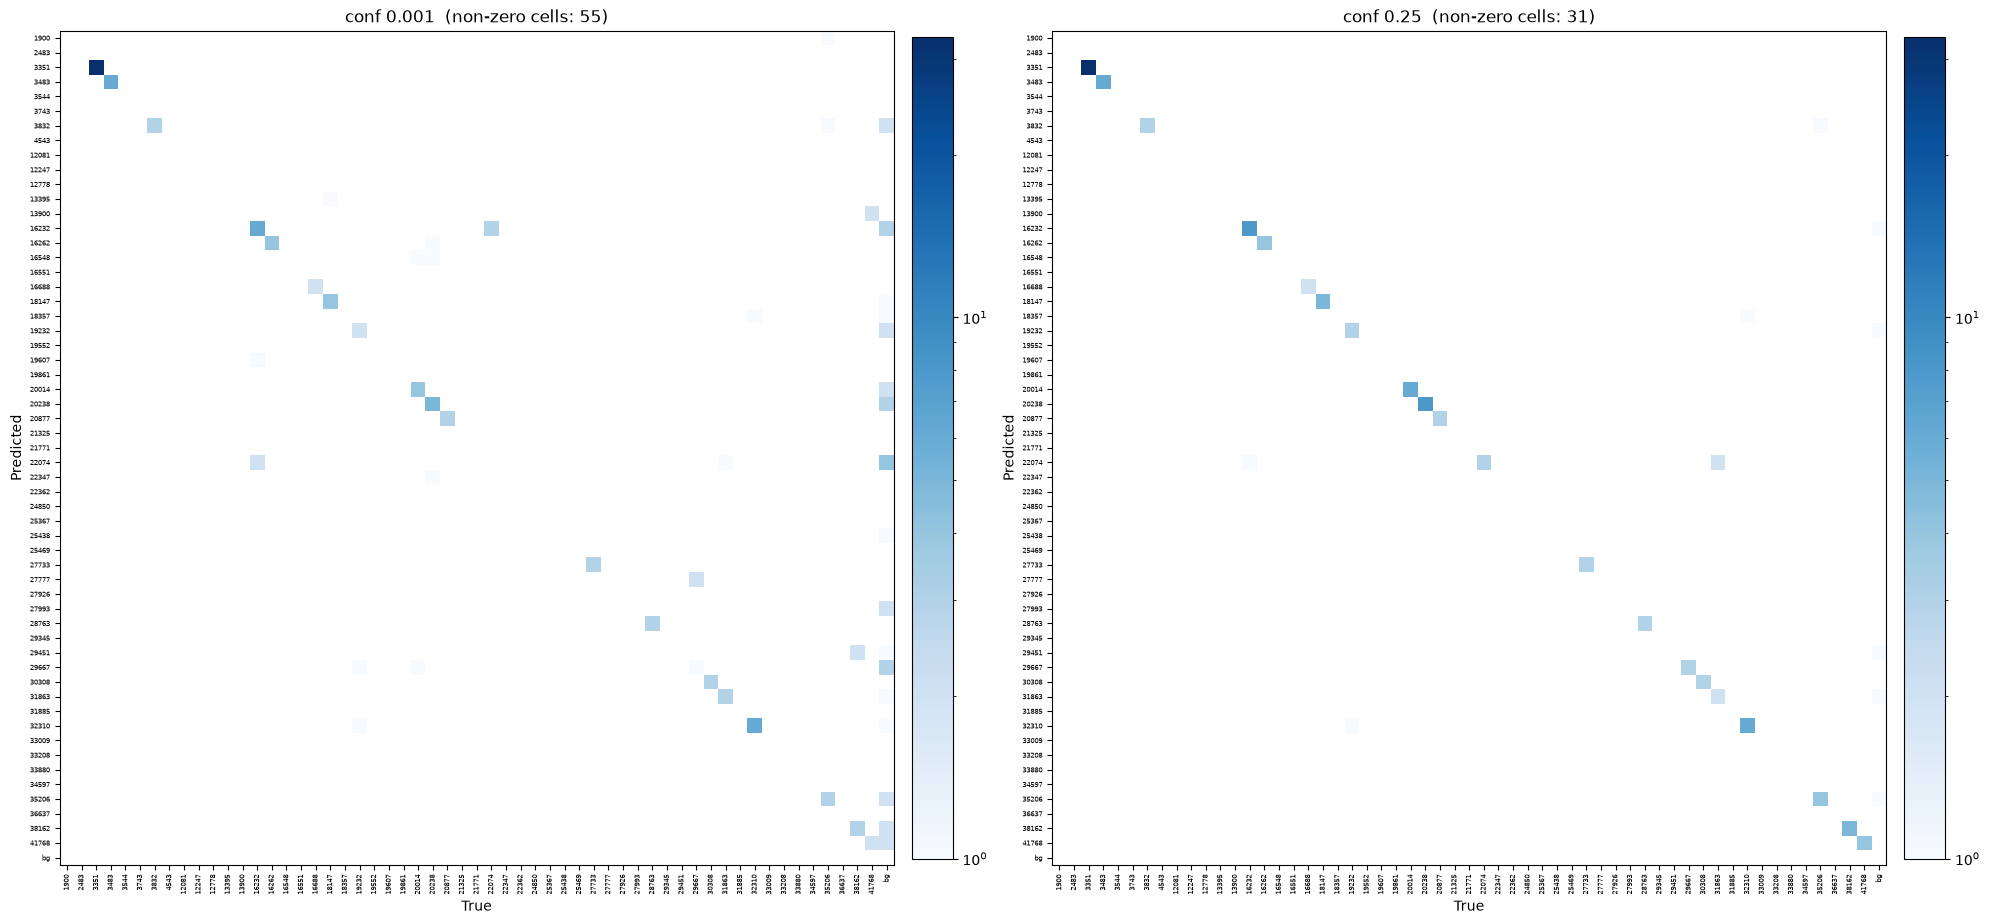

### 혼동행렬 읽는 법

행은 예측, 열은 정답이고 마지막 행·열은 배경입니다. 예측과 정답 박스는 IoU 0.45 이상일 때 짝지어집니다(ultralytics 기준).

- **맞힘**: 정답과 같은 약으로 예측 (대각선)
- **헷갈림**: 박스 위치는 맞았지만 다른 약으로 예측
- **놓침**: 정답 박스에 짝지어진 예측이 없음 (맨 아래 배경 행)
- **오검출**: 정답이 없는 곳에 예측 (맨 오른쪽 배경 열)

In [ ]:
cm_class_map = pd.concat([load_class_map(LABEL), aihub_extra_map], ignore_index=True)
n_classes = len(cm_class_map)


def cm_summary(matrix: np.ndarray) -> dict:
    """혼동행렬에서 맞힘·헷갈림·놓침·오검출 개수를 센다."""
    cls = matrix[:n_classes, :n_classes]
    return {
        "정답 박스": int(matrix[:, :n_classes].sum()),
        "맞힘": int(np.trace(cls)),
        "헷갈림": int(cls.sum() - np.trace(cls)),
        "놓침": int(matrix[n_classes, :n_classes].sum()),
        "오검출": int(matrix[:n_classes, n_classes].sum()),
        "값이 있는 칸": int((matrix > 0).sum()),
    }


cm_total = sum(cm_matrices.values())
cm_rows = [{"fold": str(fold), **cm_summary(matrix)} for fold, matrix in cm_matrices.items()]
cm_rows.append({"fold": "합계", **cm_summary(cm_total)})
pd.DataFrame(cm_rows).set_index("fold")

In [ ]:
from matplotlib.colors import LogNorm

# 0인 칸은 흰색으로 두고 값이 있는 칸만 색칠한다. 1–2개인 칸도 보이도록 색은 로그 눈금
# 축 눈금은 원본 약 번호(category_id), bg는 배경
tick_labels = [*cm_class_map["category_id"].astype(str), "bg"]
cm = cm_total  # 5 fold 합계
fig, ax = plt.subplots(figsize=(11, 10))
norm = LogNorm(vmin=1, vmax=max(cm.max(), 2))
image = ax.imshow(np.ma.masked_equal(cm, 0), cmap="Blues", norm=norm)
ax.set_title(f"conf {CM_CONF:g}, all folds  (non-zero cells: {int((cm > 0).sum())})")
ax.set_xlabel("True")
ax.set_ylabel("Predicted")
ax.set_xticks(range(len(tick_labels)), tick_labels, rotation=90, fontsize=5)
ax.set_yticks(range(len(tick_labels)), tick_labels, fontsize=5)
ax.grid(False)
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.02)
plt.tight_layout()
plt.show()

In [ ]:
# 다른 약으로 헷갈린 쌍 (5 fold 합계). 개수가 많은 순
names = cm_class_map.set_index("yolo_idx")[["category_id", "dl_name"]]
off = cm_total[:n_classes, :n_classes].copy()
np.fill_diagonal(off, 0)
pred_idx, true_idx = np.nonzero(off)
pd.DataFrame(
    {
        "정답 약": names.loc[true_idx, "category_id"].to_numpy(),
        "정답 이름": names.loc[true_idx, "dl_name"].to_numpy(),
        "예측 약": names.loc[pred_idx, "category_id"].to_numpy(),
        "예측 이름": names.loc[pred_idx, "dl_name"].to_numpy(),
        "개수": off[pred_idx, true_idx].astype(int),
    }
).sort_values("개수", ascending=False, ignore_index=True)

## 13. 비교 그림 · 표시용 conf

> 출처: **강재민**

validation 사진 최대 4장을 표시합니다. `DISPLAY_CONF`만 변경하면 평가 결과에 영향 없이 그림만 바뀝니다.
NMS IoU와 최대 탐지 수는 공통 설정을 유지합니다.

In [ ]:
for fold, weights in checkpoints.items():
    predictions = YOLO(weights).predict(
        source=[str(path) for path in val_images[fold][:4]],
        imgsz=IMGSZ,
        conf=DISPLAY_CONF,
        iou=NMS_IOU,
        max_det=MAX_DET,
        device=get_device(),
        verbose=False,
    )
    fig, axes = plt.subplots(1, len(predictions), figsize=(5 * len(predictions), 5), squeeze=False)
    for ax, prediction in zip(axes[0], predictions, strict=True):
        ax.imshow(prediction.plot()[..., ::-1])
        ax.set_title(f"{Path(prediction.path).name} / conf={DISPLAY_CONF:g}")
        ax.axis("off")
    fig.suptitle(f"fold {fold}")
    fig.tight_layout()
    plt.show()

## 14. 실패 사례 시각화 · validation

> 출처: **권영현+강재민** — 그림과 판정은 강재민, 위치 부정확(LOOSE) 분류와 약 이름 목록은 권영현

`best.pt`로 validation 전체를 예측하고, 실패가 많은 사진부터 정답과 예측을 나란히 표시합니다.
정답은 파이프라인의 보정된 YOLO 라벨을 읽습니다. 각 박스에는 약 코드(category_id)를 표시합니다.

- **TP · 초록**: 같은 클래스이고 IoU가 기준 이상인 정상 검출
- **FN · 빨강**: 대응 예측이 없는 정답, 미탐
- **FP · 보라**: 대응 정답이 없는 예측, 오탐
- **CLS · 주황**: 위치는 맞지만 클래스를 잘못 예측한 경우
- **LOOSE · 파랑**: 약은 맞지만 IoU가 `LOOSE_MATCH_IOU`(0.5) 이상 `FAILURE_MATCH_IOU`(0.75) 미만. 주 지표 mAP75-95에서는 틀린 것과 같지만, 못 찾은 것과는 다르므로 따로 셉니다 (권영현)

같은 클래스의 예측을 신뢰도 순으로 일대일 대응시킨 뒤, 남은 박스에서 오분류를 찾습니다.
같은 약이고 IoU 0.5 미만으로 어긋난 예측은 FN과 FP로 표시됩니다. CLS·LOOSE는 시각화용으로 따로 집계합니다.
`FAILURE_CONF`는 그림용 신뢰도이며 기본 `DISPLAY_CONF`를 따릅니다.
`FAILURE_MATCH_IOU=0.75`는 실패 사례 대응 기준으로, NMS IoU 0.5와 별개입니다.
이 셀은 학습·평가 지표를 변경하지 않습니다.

PNG와 실패 목록 CSV는 해당 run의 `failure_cases/` 아래 실행별 폴더에 저장합니다.

마지막 표(권영현)는 실패한 박스를 하나씩 약 이름과 함께 보여 줍니다. 어떤 약을 어떤 약으로 틀리는지 볼 때 씁니다.

In [ ]:
from datetime import datetime

from matplotlib.patches import Patch, Rectangle

FAILURE_CONF = DISPLAY_CONF  # 그림용 신뢰도. 0.001로 바꿔 낮은 점수의 검출까지 확인 가능
FAILURE_MATCH_IOU = 0.75
LOOSE_MATCH_IOU = 0.5  # 같은 약이고 IoU가 이 이상 FAILURE_MATCH_IOU 미만이면 LOOSE (권영현)
FAILURE_MAX_CASES = 6  # fold별 표시·저장할 최대 사진 수
FAILURE_COLORS = {
    "TP": "forestgreen",
    "FN": "crimson",
    "FP": "purple",
    "CLS": "darkorange",
    "LOOSE": "royalblue",
}


def failure_iou_matrix(true_boxes: np.ndarray, pred_boxes: np.ndarray) -> np.ndarray:
    """원본 이미지 xyxy 박스의 정답×예측 IoU 행렬을 계산한다."""
    true_boxes = np.asarray(true_boxes, dtype=float).reshape(-1, 4)
    pred_boxes = np.asarray(pred_boxes, dtype=float).reshape(-1, 4)
    top_left = np.maximum(true_boxes[:, None, :2], pred_boxes[None, :, :2])
    bottom_right = np.minimum(true_boxes[:, None, 2:], pred_boxes[None, :, 2:])
    intersection = np.clip(bottom_right - top_left, 0, None).prod(axis=2)
    true_area = np.clip(true_boxes[:, 2:] - true_boxes[:, :2], 0, None).prod(axis=1)
    pred_area = np.clip(pred_boxes[:, 2:] - pred_boxes[:, :2], 0, None).prod(axis=1)
    union = true_area[:, None] + pred_area[None, :] - intersection
    return np.divide(intersection, union, out=np.zeros_like(intersection), where=union > 0)


def match_failure_boxes(
    true_boxes: np.ndarray,
    true_classes: np.ndarray,
    pred_boxes: np.ndarray,
    pred_classes: np.ndarray,
    pred_scores: np.ndarray,
    match_iou: float,
    loose_iou: float,
) -> dict:
    """정상 검출을 먼저 일대일 대응한 뒤 남은 오분류·위치 부정확·미탐·오탐을 구분한다."""
    overlaps = failure_iou_matrix(true_boxes, pred_boxes)
    true_status = np.full(len(true_classes), "FN", dtype="U5")
    pred_status = np.full(len(pred_classes), "FP", dtype="U5")
    true_match = np.full(len(true_classes), -1, dtype=int)
    pred_match = np.full(len(pred_classes), -1, dtype=int)
    order = np.argsort(-pred_scores, kind="stable")
    passes = ((True, "TP", match_iou), (False, "CLS", match_iou), (True, "LOOSE", loose_iou))
    for same_class, status, min_iou in passes:
        for pred_index in order:
            if pred_match[pred_index] >= 0:
                continue
            eligible = (
                (true_match < 0)
                & (overlaps[:, pred_index] >= min_iou)
                & ((true_classes == pred_classes[pred_index]) == same_class)
            )
            candidates = np.flatnonzero(eligible)
            if not len(candidates):
                continue
            true_index = candidates[np.argmax(overlaps[candidates, pred_index])]
            true_match[true_index], pred_match[pred_index] = pred_index, true_index
            true_status[true_index] = pred_status[pred_index] = status
    return {
        "true_status": true_status,
        "pred_status": pred_status,
        "true_match": true_match,
        "pred_match": pred_match,
        "iou": overlaps,
    }


def draw_failure_case(case: dict, class_codes: dict[int, str], output_path: Path) -> None:
    """실패 사진의 정답과 예측을 나란히 그리고 색으로 구분해 저장·표시한다."""
    image = plt.imread(case["image_path"])
    fig, axes = plt.subplots(1, 2, figsize=(13, 8))
    matches = case["matches"]
    for ax, title, boxes, classes, statuses, is_prediction in (
        (
            axes[0],
            "Ground truth",
            case["true_boxes"],
            case["true_classes"],
            matches["true_status"],
            False,
        ),
        (
            axes[1],
            "Prediction",
            case["pred_boxes"],
            case["pred_classes"],
            matches["pred_status"],
            True,
        ),
    ):
        ax.imshow(image)
        for index, (box, cls, status) in enumerate(zip(boxes, classes, statuses, strict=True)):
            x1, y1, x2, y2 = box
            color = FAILURE_COLORS[status]
            ax.add_patch(
                Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=2)
            )
            label = f"{status} {class_codes.get(int(cls), str(int(cls)))}"
            if is_prediction:
                label += f" conf={case['pred_scores'][index]:.3f}"
                if len(case["true_boxes"]):
                    true_index = matches["pred_match"][index]
                    iou = (
                        matches["iou"][true_index, index]
                        if true_index >= 0
                        else matches["iou"][:, index].max()
                    )
                    label += f"\n{'IoU' if true_index >= 0 else 'maxIoU'}={iou:.2f}"
            ax.text(
                x1,
                max(y1 - 4, 0),
                label,
                color=color,
                fontsize=9,
                va="bottom",
                bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"},
            )
        ax.set_title(title)
        ax.axis("off")
    fig.suptitle(
        f"fold {case['fold']} / {case['file_name']}\n"
        f"FN={case['fn']} FP={case['fp']} CLS={case['cls']} LOOSE={case['loose']} | "
        f"conf={FAILURE_CONF:g}, match IoU={FAILURE_MATCH_IOU:g}"
    )
    fig.legend(
        handles=[Patch(color=color, label=status) for status, color in FAILURE_COLORS.items()],
        loc="lower center",
        ncol=len(FAILURE_COLORS),
    )
    fig.tight_layout(rect=(0, 0.04, 1, 0.94))
    fig.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


@torch.no_grad()
def visualize_failures(
    weights: Path, images: list[Path], fold: int
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """validation 실패를 집계하고 그림·CSV를 저장해 (사진별 표, 박스별 표)를 반환한다."""
    if not 0 <= FAILURE_CONF <= 1 or not 0 < FAILURE_MATCH_IOU <= 1 or FAILURE_MAX_CASES < 1:
        raise ValueError("conf는 0~1, 대응 IoU는 0 초과 1 이하, 표시 개수는 1 이상이어야 합니다.")
    output_dir = (
        weights.parent.parent / "failure_cases" / f"conf{FAILURE_CONF:g}_iou{FAILURE_MATCH_IOU:g}"
    )
    output_dir = output_dir / datetime.now().strftime("review_%Y%m%d_%H%M%S_%f")
    output_dir.mkdir(parents=True, exist_ok=False)
    class_map = pd.concat([load_class_map(LABEL), aihub_extra_map], ignore_index=True)
    class_codes = dict(
        zip(class_map["yolo_idx"], class_map["category_id"].astype(str), strict=True)
    )
    failures, box_rows = [], []
    predictions = YOLO(weights).predict(
        source=[str(path) for path in images],
        stream=True,
        batch=BATCH,
        imgsz=IMGSZ,
        conf=FAILURE_CONF,
        iou=NMS_IOU,
        max_det=MAX_DET,
        device=get_device(),
        verbose=False,
    )
    for result in tqdm(
        predictions, total=len(images), desc=f"fold {fold} / failure review", unit="image"
    ):
        file_name = Path(result.path).name
        height, width = result.orig_shape
        label_path = yolo_dir(LABEL) / "labels" / "train" / Path(file_name).with_suffix(".txt").name
        truth = read_yolo_labels(label_path, width, height)
        true_boxes = truth[["x", "y", "w", "h"]].to_numpy(dtype=float, copy=True)
        true_boxes[:, 2:] += true_boxes[:, :2]
        true_classes = truth["yolo_idx"].to_numpy(dtype=int)
        pred_boxes = result.boxes.xyxy.detach().cpu().numpy()
        pred_classes = result.boxes.cls.detach().cpu().numpy().astype(int)
        pred_scores = result.boxes.conf.detach().cpu().numpy()
        matches = match_failure_boxes(
            true_boxes,
            true_classes,
            pred_boxes,
            pred_classes,
            pred_scores,
            FAILURE_MATCH_IOU,
            LOOSE_MATCH_IOU,
        )
        counts = {
            "fn": int((matches["true_status"] == "FN").sum()),
            "fp": int((matches["pred_status"] == "FP").sum()),
            "cls": int((matches["pred_status"] == "CLS").sum()),
            "loose": int((matches["pred_status"] == "LOOSE").sum()),
        }
        # 박스별 실패 목록 (권영현): 놓친 정답과 정답이 아닌 예측을 한 줄씩
        for true_index in np.flatnonzero(matches["true_status"] == "FN"):
            box_rows.append(
                {
                    "fold": fold,
                    "file_name": file_name,
                    "kind": "FN",
                    "true": class_codes[int(true_classes[true_index])],
                    "pred": None,
                    "iou": np.nan,
                    "conf": np.nan,
                }
            )
        for pred_index in np.flatnonzero(matches["pred_status"] != "TP"):
            true_index = matches["pred_match"][pred_index]
            column = matches["iou"][:, pred_index]
            box_rows.append(
                {
                    "fold": fold,
                    "file_name": file_name,
                    "kind": str(matches["pred_status"][pred_index]),
                    "true": class_codes[int(true_classes[true_index])] if true_index >= 0 else None,
                    "pred": class_codes[int(pred_classes[pred_index])],
                    "iou": float(column[true_index] if true_index >= 0 else column.max(initial=0)),
                    "conf": float(pred_scores[pred_index]),
                }
            )
        if not any(counts.values()):
            continue
        false_scores = pred_scores[matches["pred_status"] != "TP"]
        failures.append(
            {
                "fold": fold,
                "file_name": file_name,
                "image_path": str(result.path),
                **counts,
                "errors": sum(counts.values()),
                "max_false_conf": float(false_scores.max()) if len(false_scores) else 0.0,
                "true_boxes": true_boxes,
                "true_classes": true_classes,
                "pred_boxes": pred_boxes,
                "pred_classes": pred_classes,
                "pred_scores": pred_scores,
                "matches": matches,
            }
        )
    failures.sort(key=lambda case: (-case["errors"], -case["max_false_conf"], case["file_name"]))
    columns = ["fold", "file_name", "fn", "fp", "cls", "loose", "errors", "max_false_conf"]
    table = pd.DataFrame(
        [{key: case[key] for key in columns} for case in failures], columns=columns
    )
    table.to_csv(output_dir / "failure_cases.csv", index=False, encoding="utf-8")
    print(f"fold {fold}: validation {len(images)}장 중 실패 {len(failures)}장 / 저장: {output_dir}")
    boxes = pd.DataFrame(
        box_rows, columns=["fold", "file_name", "kind", "true", "pred", "iou", "conf"]
    )
    if table.empty:
        print("현재 그림용 conf와 IoU 기준에서 실패 사례가 없습니다.")
        return table, boxes
    display(table.head(FAILURE_MAX_CASES).round(4))
    for rank, case in enumerate(failures[:FAILURE_MAX_CASES], 1):
        draw_failure_case(
            case, class_codes, output_dir / f"{rank:02d}_{Path(case['file_name']).stem}.png"
        )
    return table, boxes

In [ ]:
if "checkpoints" not in globals() or not checkpoints:
    raise RuntimeError("학습이 끝난 커널에서 실행하세요. checkpoints에 best.pt 경로가 필요합니다.")
failure_tables, failure_boxes = {}, []
for fold, weights in checkpoints.items():
    failure_tables[fold], fold_boxes = visualize_failures(weights, val_images[fold], fold)
    failure_boxes.append(fold_boxes)

# 실패한 박스 목록 (권영현): 약 이름을 붙여 어떤 약을 어떤 약으로 틀렸는지 본다
name_of = dict(zip(cm_class_map["category_id"].astype(str), cm_class_map["dl_name"], strict=True))
failure_boxes = pd.concat(failure_boxes, ignore_index=True)
if failure_boxes.empty:
    print("실패한 박스가 없습니다.")
else:
    failure_boxes["true_name"] = failure_boxes["true"].map(name_of)
    failure_boxes["pred_name"] = failure_boxes["pred"].map(name_of)
    print(failure_boxes["kind"].value_counts().to_string())
    display(failure_boxes.sort_values(["kind", "fold", "file_name"]).round(3))

## 15. 대회 제출 csv

> 출처: **저장소 템플릿** — `experiment_template.ipynb` 9번과 같은 제출 형식(`models/evaluate.to_submission`)을 씁니다. 외부 전용 클래스 예측은 버리지 않고 AI Hub 약 코드(category_id)로 바꿔 제출합니다. 정답표에 그 약이 없으면 감점됩니다.

fold 0의 best.pt로 test 사진을 예측해 제출 형식 `annotation_id, image_id, category_id, bbox_x, bbox_y, bbox_w, bbox_h, score` csv를 저장합니다. 저장 경로는 아래 출력에 나옵니다. Colab·Kaggle 런타임이 끝나면 사라지니(Kaggle은 커밋하면 출력 탭에 남습니다) 내려받아 두세요.
드라이브 복사 폴더는 `yolo11m_epoch100_aihub_submission`입니다. run 이름이 100 에폭 베이스라인과 같아 같은 폴더에 두면 파일을 덮어쓰기 때문입니다.

In [ ]:
from ultralytics import YOLO

from data_process.data_yaml import load_class_map, yolo_dir
from models.evaluate import PRED_COLS, results_dir, to_submission
from src.config import get_device

SUBMIT_FOLD = FOLDS[0]  # 팀 템플릿과 같이 fold 0의 best.pt로 제출한다
SUBMIT_CONF = 0.001  # 검증과 같은 값. 대회는 mAP 채점이라 점수 낮은 박스도 남긴다


def make_competition_submission(weights, exp, imgsz, conf, runs_dir):
    """models.evaluate.make_submission과 같은 제출 csv를 쓴다. 외부 전용 클래스 예측은 버리지 않고
    AI Hub 약 코드(category_id)로 바꿔 제출한다. 대회 category_id와 약 코드 숫자는 같은 체계다.
    """
    class_map = pd.concat([load_class_map(LABEL), aihub_extra_map], ignore_index=True)
    to_category = dict(zip(class_map["yolo_idx"], class_map["category_id"], strict=True))
    rows = []
    for result in YOLO(weights).predict(
        source=str(yolo_dir(LABEL) / "images" / "test"),
        imgsz=imgsz,
        conf=conf,
        iou=0.7,
        device=get_device(),
        stream=True,
        verbose=False,
    ):
        file_name = Path(result.path).name
        for (x1, y1, x2, y2), cls, score in zip(
            result.boxes.xyxy.tolist(),
            result.boxes.cls.int().tolist(),
            result.boxes.conf.tolist(),
            strict=True,
        ):
            rows.append([file_name, cls, to_category[cls], x1, y1, x2 - x1, y2 - y1, score])
    sub = to_submission(pd.DataFrame(rows, columns=PRED_COLS))
    stem = Path(weights).parent.parent.name
    out_path = results_dir(exp, runs_dir) / f"{stem}_submission_conf{conf:g}.csv"
    out_path.parent.mkdir(parents=True, exist_ok=True)
    sub.to_csv(out_path, index=False, encoding="utf-8")
    return sub, out_path


if "checkpoints" not in globals() or SUBMIT_FOLD not in checkpoints:
    raise RuntimeError(
        "학습이 끝난 커널에서 실행하세요. checkpoints에 SUBMIT_FOLD의 best.pt가 필요합니다."
    )

submission, submission_path = make_competition_submission(
    checkpoints[SUBMIT_FOLD], OUTPUT_NAME, IMGSZ, SUBMIT_CONF, output_root
)
print(f"사진 {submission['image_id'].nunique()}장, 박스 {len(submission)}개")
print(f"저장 {submission_path}")
submission.head()


In [ ]:
# 제출 csv를 따로 보관한다. Colab은 구글 드라이브로, Kaggle은 /kaggle/working으로 복사한다.
import shutil

try:
    if IN_COLAB:
        from google.colab import drive

        drive.mount("/content/drive")
        save_root = Path("/content/drive/MyDrive")
    elif IN_KAGGLE:
        save_root = Path("/kaggle/working")
    else:
        save_root = None
    if save_root is None:
        print("로컬 실행: 제출 csv는 위 경로에 이미 저장되어 있습니다.")
    else:
        # 100 에폭 베이스라인과 run 이름이 같아 실험 이름 폴더로 나눈다
        save_dir = save_root / f"{OUTPUT_NAME}_submission"
        save_dir.mkdir(parents=True, exist_ok=True)
        copied = shutil.copy(submission_path, save_dir / Path(submission_path).name)
        print(f"복사 완료: {copied}")
except Exception as e:
    print("복사 실패:", type(e).__name__, str(e)[:300])

## 16. fold별 제출 csv와 best.pt를 저장

fold마다 `best.pt`로 test 제출 csv를 만들어 저장합니다. fold끼리 평균하지 않습니다. 5 fold 학습이 모두 끝난 뒤에 실행하세요.

- Colab: csv와 `best.pt`를 구글 드라이브 `yolo11m_epoch100_aihub_submission_per_fold` 폴더에 저장합니다.
- Kaggle: csv만 `/kaggle/working/yolo11m_epoch100_aihub_submission_per_fold`에 저장합니다 (`best.pt`는 이미 `pillbbox_runs`에 있어 디스크를 아끼려고 다시 복사하지 않습니다). 커밋하면 출력 탭에서 받을 수 있습니다.

In [ ]:
# fold마다 test 제출 csv를 만들어 구글 드라이브에 저장한다. fold끼리 평균하지 않는다.
import shutil

# 45단계의 make_competition_submission을 쓴다
SUBMIT_CONF = 0.001  # 검증과 같은 값. 대회는 mAP 채점이라 점수 낮은 박스도 남긴다

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    save_root = Path("/content/drive/MyDrive")
else:
    save_root = Path("/kaggle/working") if IN_KAGGLE else PROJECT_ROOT / "runs"
# 100 에폭 베이스라인의 fold{k}_best.pt를 덮어쓰지 않도록 실험 이름 폴더로 나눈다
drive_dir = save_root / f"{OUTPUT_NAME}_submission_per_fold"
drive_dir.mkdir(parents=True, exist_ok=True)

for fold in FOLDS:
    weights = (
        output_root
        / OUTPUT_NAME
        / f"{SPLIT}_MuSGD_lr{LR0:g}_e{epochs}_p{PATIENCE}_fold{fold}"
        / "weights"
        / "best.pt"
    )
    if not weights.is_file():
        raise FileNotFoundError(f"fold {fold}의 best.pt가 없습니다: {weights}")
    submission, submission_path = make_competition_submission(
        weights, OUTPUT_NAME, IMGSZ, SUBMIT_CONF, output_root
    )
    copied_csv = shutil.copy(submission_path, drive_dir / submission_path.name)
    # Kaggle은 best.pt가 이미 /kaggle/working에 있어 디스크를 아끼려고 복사하지 않는다
    copied_pt = None if IN_KAGGLE else shutil.copy(weights, drive_dir / f"fold{fold}_best.pt")
    print(f"fold {fold}: 사진 {submission['image_id'].nunique()}장, 박스 {len(submission)}개")
    print(f"  저장: {copied_csv}")
    if copied_pt is not None:
        print(f"  저장: {copied_pt}")

## 병합 기록

| 단계 | 출처 | 메모 |
|---|---|---|
| 1. 설정 | 강재민 | 권영현의 `CM_CONF`, `AUG_PRESET` 추가. 강재민의 `CONFUSION_CONFS` 제거 |
| 2. Colab 준비 | 강재민 | |
| 3. 환경 | 강재민 | 진행 막대를 `tqdm.auto`에서 텍스트 `tqdm`으로 변경 (권영현) |
| 4. 데이터 생성과 분할 | 강재민 | 권영현의 직접 작성 데이터 준비(보정·분할·YOLO 변환)는 쓰지 않음 |
| 5. 데이터 검사 | 강재민 | 5-1 박스 그림은 권영현 |
| 5-2. 외부 데이터 | 02_eda | 100 에폭 + AI Hub 실험에서 추가. 02_eda §1·2·5·6·7·8 선별·검사를 옮기고 사진 통째 사용·외부 전용 알약은 배경이 아닌 새 클래스로 학습(`AIHUB_EXTRA_AS_CLASS`)·YOLO 변환·fold별 train 목록을 더함 |
| 6. 학습 루프 | 권영현+강재민 | 학습 루프·체크포인트·early stopping은 강재민, `GradCheck`는 권영현. 권영현의 `Map7595Trainer`·`EpochProgress`는 쓰지 않음 |
| 7. 학습 실행 | 강재민 | 기울기 기록 표는 권영현 |
| 8. 에폭별 시간 | 강재민 | |
| 9. 학습 곡선 | 권영현+강재민 | 9-1 fold별 상세는 권영현, 9-2 대시보드는 강재민. 강재민의 fold별 간단 곡선은 9-1로 대체 |
| 10. 평가 | 강재민 | mAP50·mAP50-95 열은 권영현. 혼동행렬은 `CM_CONF` 하나만 평가 |
| 11. 과적합 점검 | 권영현 | 5 fold로 확장 |
| 12. 혼동행렬 | 권영현 | 5 fold 합계로 확장. 강재민의 0.001·0.25 ultralytics 그림 표시는 대체 (CSV 저장은 강재민 그대로) |
| 13. 비교 그림 | 강재민 | |
| 14. 실패 사례 | 권영현+강재민 | 그림과 판정은 강재민, LOOSE 분류와 박스별 약 이름 목록은 권영현 |
| 15. 대회 제출 csv | 저장소 템플릿 | `models/evaluate.make_submission`과 같은 형식(`SUBMISSION_COLS`)으로 쓰되, 외부 전용 예측은 AI Hub 약 코드로 바꿔 넣음 (`make_competition_submission`) |
| Kaggle 변환 | 이 노트북 | `IN_KAGGLE` 분기 추가: 저장소 clone·패키지 설치·Kaggle Secrets·결과 폴더 `/kaggle/working`·제출 저장. Colab도 그대로 동작 |
| 17. 이어서 학습·커널 종료 | 이 노트북 | 끊긴 fold를 `last.pt`에서 이어 학습, 모든 fold가 끝나면 런타임 종료(Colab) 또는 세션 자동 종료 안내(Kaggle) |


## 17. 끊긴 학습 이어서 하기 · 학습이 끝나면 커널 종료

커널이 중간에 죽어 7단계 학습이 끊겼을 때 쓰는 셀입니다. fold마다 상태를 보고 알아서 처리합니다.

| fold 상태 | 처리 |
|---|---|
| 학습이 끝남 (`last.pt`에 optimizer가 없음) | 건너뜀 |
| `last.pt`가 있고 끝나지 않음 | 마지막으로 저장된 에폭부터 `resume=True`로 이어서 학습 |
| 결과 폴더가 없거나 `last.pt`가 없음 | 처음부터 학습 |

**끊긴 뒤 순서**: 커널 재시작 → 1~6단계 셀(설정·환경·EDA 검사·5-2 외부 데이터·학습 루프)만 다시 실행 (7단계 학습 셀은 실행하지 않음) → 아래 이어서 학습 셀 → 8~16단계 → 맨 아래 커널 종료 셀.

- 이어 학습할 때 에폭·patience·증강 등은 `last.pt`에 저장된 값을 따릅니다. 설정 셀을 바꿨어도 끊긴 fold에는 반영되지 않습니다.
- 에폭 시간(`epoch_times.csv`)은 이어서 기록합니다. 7단계의 기울기 확인 표(`grad_table`)는 이어 학습한 구간부터만 쌓입니다.
- 모든 fold가 끝난 상태에서 실행하면 아무것도 학습하지 않고 `checkpoints`·`run_dirs`만 채웁니다.
- 마지막 셀은 모든 fold의 학습이 끝난 것을 확인한 뒤에만 종료를 처리합니다. `KILL_KERNEL_WHEN_DONE = False`면 종료하지 않습니다.
  - Colab: 런타임을 반납합니다 (`runtime.unassign()`).
  - Kaggle 커밋(Save & Run All): 노트북이 끝나면 세션이 자동으로 끝나므로 아무것도 하지 않습니다. 커널을 강제로 죽이면 실행이 실패로 기록될 수 있습니다.
  - Kaggle 대화형 세션: 코드로 세션을 멈출 방법이 없습니다. GPU 메모리만 비우고, 오른쪽 Session 패널에서 **Stop Session**을 직접 누르라고 안내합니다.
- Kaggle 커밋 실행에서 커널이 죽으면 그 실행은 그대로 끝납니다. 이어서 하려면 그 버전의 Output을 Add Input으로 붙이고 `KAGGLE_PREV_RUNS`를 설정한 새 실행에서 이 셀을 쓰세요.

In [ ]:
# 끊긴 학습을 이어서 한다. 끝난 fold는 건너뛰고, 안 끝난 fold는 last.pt에서 이어 학습한다.
# 7단계 학습 셀 대신 실행하는 셀이다 (1~6단계 셀은 먼저 실행해 둘 것).
if list(folds) != ([FOLDS[0]] if SMOKE else list(FOLDS)):
    raise RuntimeError("FOLDS 설정이 바뀌었습니다. 환경·데이터 준비·EDA 검사 셀을 다시 실행하세요.")
if "data_audit" not in globals() or "train_data_paths" not in globals():
    raise RuntimeError("EDA 검사 셀과 외부 데이터 셀(5-2)을 먼저 실행하세요.")
if "NotebookTrainer" not in globals():
    raise RuntimeError("6단계 학습 루프 셀을 먼저 실행하세요.")


def fold_run_name(fold: int) -> str:
    return f"{SPLIT}_MuSGD_lr{LR0:g}_e{epochs}_p{PATIENCE}_fold{fold}"


def fold_state(run_dir: Path) -> str:
    """'done' 학습 끝, 'resume' 이어서 가능, 'fresh' 처음부터."""
    last = run_dir / "weights" / "last.pt"
    if not last.is_file():
        return "fresh"
    try:
        ckpt = torch.load(last, map_location="cpu", weights_only=False)
    except Exception as error:  # 저장 도중 죽어 파일이 깨졌을 수 있다
        print(f"  last.pt를 읽지 못했습니다 ({error!r}). epochN.pt가 있으면 그것으로 이어가세요.")
        raise
    # 학습이 정상 종료되면 ultralytics가 last.pt의 optimizer를 지운다 (strip_optimizer)
    finished = ckpt.get("optimizer") is None and (run_dir / "weights" / "best.pt").is_file()
    return "done" if finished else "resume"


def attach_callbacks(model: YOLO, fold: int) -> tuple[EpochTimer, GradCheck]:
    model.add_callback("on_train_start", record_data_audit)
    epoch_timer = EpochTimer(fold)
    model.add_callback("on_train_start", epoch_timer.on_train_start)
    model.add_callback("on_train_epoch_start", epoch_timer.on_epoch_start)
    model.add_callback("on_fit_epoch_end", epoch_timer.on_epoch_end)
    grad_check = GradCheck(fold)
    model.add_callback("on_train_epoch_start", grad_check.on_epoch_start)
    model.add_callback("on_train_batch_end", grad_check.on_train_batch_end)
    model.add_callback("on_val_batch_end", grad_check.on_val_batch_end)
    model.add_callback("on_fit_epoch_end", grad_check.on_epoch_end)
    return epoch_timer, grad_check


device = get_device()
if not SMOKE and device != "cuda":
    raise RuntimeError("GPU에 접근하지 못했습니다. 환경 셀의 GPU 확인 결과를 보세요.")

checkpoints = {}
run_dirs = {}
grad_rows = []
for fold in folds:
    run_dir = output_root / OUTPUT_NAME / fold_run_name(fold)
    state = fold_state(run_dir)
    print(f"fold {fold}: {state} ({run_dir})")
    if state == "done":
        checkpoints[fold], run_dirs[fold] = run_dir / "weights" / "best.pt", run_dir
        continue

    if state == "resume":
        model = YOLO(run_dir / "weights" / "last.pt")
        epoch_timer, grad_check = attach_callbacks(model, fold)
        times_csv = run_dir / "epoch_times.csv"
        if times_csv.is_file():  # 끊기기 전 에폭 시간을 이어서 쌓는다
            epoch_timer.rows = pd.read_csv(times_csv).to_dict("records")
        train_kwargs = {"resume": True}
    else:
        model = YOLO(MODEL)
        epoch_timer, grad_check = attach_callbacks(model, fold)
        train_kwargs = {
            **AUGMENTATION,
            "data": str(train_data_paths[fold]),
            "epochs": epochs,
            "imgsz": IMGSZ,
            "batch": BATCH,
            "seed": SEED,
            "deterministic": True,
            "fraction": fraction,
            "optimizer": OPTIMIZER,
            "lr0": LR0,
            "patience": PATIENCE,
            "freeze": None,
            "val": True,
            "save": True,
            "save_period": CHECKPOINT_PERIOD,
            "plots": True,
            "conf": EVAL_CONF,
            "iou": NMS_IOU,
            "max_det": MAX_DET,
            "device": device,
            "project": str(output_root / OUTPUT_NAME),
            "name": fold_run_name(fold),
            "exist_ok": True,  # last.pt가 없는 빈 폴더가 남아 있어도 같은 폴더에 시작
        }
    run = (
        init_wandb(
            model,
            run_name=fold_run_name(fold),
            config={**train_kwargs, "data_fingerprint": data_audit["fingerprint"]},
        )
        if WANDB and not SMOKE
        else None
    )
    try:
        model.train(trainer=NotebookTrainer, **train_kwargs)
    finally:
        epoch_timer.close()
        if run is not None:
            run.finish()

    save_dir = Path(model.trainer.save_dir)
    if save_dir.resolve() != run_dir.resolve():
        raise RuntimeError(f"결과 폴더가 달라졌습니다: {save_dir} (기대: {run_dir})")
    best_path = save_dir / "weights" / "best.pt"
    if not best_path.is_file():
        raise FileNotFoundError(f"best.pt가 저장되지 않았습니다: {best_path}")
    (save_dir / "notebook_config.json").write_text(
        json.dumps(
            {
                "train": {k: v for k, v in vars(model.trainer.args).items() if k != "save_dir"},
                "resumed": state == "resume",
                "cm_conf": CM_CONF,
                "display_conf": DISPLAY_CONF,
                "data_fingerprint": data_audit["fingerprint"],
                "ultralytics": ultralytics.__version__,
                "torch": torch.__version__,
            },
            ensure_ascii=False,
            indent=2,
            default=str,
        ),
        encoding="utf-8",
    )
    checkpoints[fold], run_dirs[fold] = best_path, save_dir
    grad_rows.extend(grad_check.rows)
    print(f"fold {fold} best.pt: {best_path}")

if grad_rows:
    grad_table = pd.DataFrame(grad_rows)
    grad_ok = bool(grad_table["학습 중 기울기"].all() and not grad_table["검증 중 기울기"].any())
    print("기울기 확인:", "학습 중 켜짐, 검증 중 꺼짐" if grad_ok else "확인 필요")
print(f"학습 완료 fold: {sorted(checkpoints)}")

In [ ]:
# 학습이 모두 끝나면 커널·런타임 종료를 처리해 GPU를 아낀다. 맨 마지막에 실행한다.
# Colab·로컬은 종료하고, Kaggle은 세션 자동 종료(커밋) 또는 Stop Session 안내만 한다.
import gc
import time

KILL_KERNEL_WHEN_DONE = True  # False면 종료하지 않고 상태만 확인한다
KILL_DELAY_SEC = 30  # 종료 전 대기(Colab·로컬). 이 사이에 셀을 중단(■)하면 종료되지 않는다

# 모든 fold의 학습이 정상 종료(best.pt 있음, last.pt의 optimizer 제거)됐을 때만 종료한다
unfinished = []
for fold in folds:
    weights_dir = output_root / OUTPUT_NAME / fold_run_name(fold) / "weights"
    try:
        ckpt = torch.load(weights_dir / "last.pt", map_location="cpu", weights_only=False)
        finished = ckpt.get("optimizer") is None and (weights_dir / "best.pt").is_file()
    except Exception:
        finished = False
    if not finished:
        unfinished.append(fold)

if unfinished:
    print(
        f"fold {unfinished} 학습이 끝나지 않아 커널을 종료하지 않습니다. 위 이어서 학습 셀을 실행하세요."
    )
elif not KILL_KERNEL_WHEN_DONE:
    print("모든 fold 학습 완료. KILL_KERNEL_WHEN_DONE=False라 종료하지 않습니다.")
else:
    gc.collect()
    torch.cuda.empty_cache()
    if IN_KAGGLE:
        # Kaggle은 코드로 세션을 반납할 수 없다. 커밋은 노트북이 끝나면 세션이 자동으로 끝나고,
        # 커널을 강제로 죽이면 실행이 실패로 기록될 수 있어 아무것도 죽이지 않는다.
        if os.getenv("KAGGLE_KERNEL_RUN_TYPE") == "Batch":
            print("모든 fold 학습 완료. 이 셀이 끝나면 커밋 실행과 세션이 자동으로 종료됩니다.")
        else:
            print(
                "모든 fold 학습 완료. 대화형 세션은 코드로 멈출 수 없습니다. "
                "GPU 시간을 아끼려면 오른쪽 Session 패널에서 Stop Session을 눌러 주세요."
            )
    else:
        print(f"모든 fold 학습 완료. {KILL_DELAY_SEC}초 뒤 종료합니다 (중단하려면 셀 중지).")
        time.sleep(KILL_DELAY_SEC)
        if IN_COLAB:
            from google.colab import drive, runtime

            drive.flush_and_unmount()  # 드라이브 쓰기를 마무리한 뒤 런타임 반납(GPU 할당 해제)
            runtime.unassign()
        else:
            os._exit(0)  # 로컬: 커널 프로세스를 끝낸다